# 5. Много метрик — одно решение

В отчёте теста двадцать метрик: целевая выросла, время доставки чуть хуже, три диагностические метрики «значимы», а в одном сегменте эффект вдвое больше среднего. Базовый рецепт «посчитать p-value для каждой метрики и сравнить с 0.05» здесь ломается: при двадцати проверках хотя бы одна случайная «победа» почти гарантирована, а противоречащие друг другу метрики сами в решение не складываются. На встрече разберём порядок чтения такого отчёта: сначала проверить сплит, затем разложить метрики по ролям, понять, к каким из них нужна поправка на множественность и какая, и посмотреть на сегменты без подгонки под значимость. После встречи вы сможете по такому отчёту принять и обосновать одно из трёх решений: внедряем, не внедряем или внедряем с условием.

### Библиотеки

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as st
import seaborn as sns
from ipywidgets import FloatSlider, IntSlider, interact
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from matplotlib.ticker import PercentFormatter
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import TTestIndPower
from tqdm import tqdm

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
PURPLE, ORANGE = '#8172B3', '#DD8452'

# Один метод на всех графиках имеет один цвет и один маркер
METHOD_STYLE = {
    'Без поправки': ('#8a8a85', 'o'),
    'Бонферрони': ('#2a78d6', 's'),
    'Холм': ('#eb6834', '^'),
    'Шидак': ('#1baf7a', 'D'),
    'BH': ('#eda100', 'v'),
    'BY': ('#e87ba4', 'P'),
}
REAL_COLOR, NULL_COLOR = '#2a78d6', '#eb6834'  # гипотезы с реальным эффектом и без него
REFERENCE_COLOR = '#52514e'                    # линии α и β

In [2]:
def diff_p(a, b):
    """Разность средних b - a, её стандартная ошибка и p-value (критерий Уэлча)."""
    delta = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    return delta, se, 2 * st.norm.sf(abs(delta / se))


def rel_effect(a, b):
    """Относительный эффект b/a - 1 и его стандартная ошибка (дельта-метод, независимые группы)."""
    ma, mb = a.mean(), b.mean()
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    return mb / ma - 1, np.sqrt(vb / ma ** 2 + va * mb ** 2 / ma ** 4)


def ratio_effect(num_a, den_a, num_b, den_b):
    """Относительный эффект ratio-метрики sum(num)/sum(den) и его стандартная ошибка (линеаризация)."""
    ra, rb = num_a.sum() / den_a.sum(), num_b.sum() / den_b.sum()

    def var(num, den, r):
        return ((num - r * den) / den.mean()).var(ddof=1) / len(num)

    se = np.sqrt(var(num_b, den_b, rb) / ra ** 2 + var(num_a, den_a, ra) * rb ** 2 / ra ** 4)
    return rb / ra - 1, se


def pct(x, digits=1):
    return f'{100 * x:+.{digits}f}%'

## Сквозной кейс и роли метрик

Все примеры встречи живут в одном продукте: приложении доставки еды. Главная цель бизнеса — чтобы пользователи заказывали больше и дольше оставались. Мы формулируем её как **долгосрочную метрику (north star)**: число заказов на пользователя за 28 дней. Проблема в том, что узнать её можно только через четыре недели, а тест нужно закончить раньше. Поэтому в тесте мы смотрим не на одну метрику, а на несколько, и у каждой своя роль.

Роли удобно разделять по тому, **что мы с метрикой делаем**. Эта классификация из статьи Microsoft ([Dmitriev и др., 2017](https://www.microsoft.com/en-us/research/uploads/prod/2020/08/2017-08-KDDMetricInterpretationPitfalls.pdf)) дополняет разбиение success/guardrail/deterioration/quality из фреймворка Spotify, который мы разберём ниже в разделе «На какую метрику смотреть?»: она отвечает на вопрос «в каком порядке читать результат», а не «как считать поправки».

* **Метрики качества данных.** Первый вопрос: можно ли вообще доверять эксперименту. Главная из них — доля пользователей в группах, то есть SRM (sample ratio mismatch, несовпадение долей групп с планом). Сюда же относятся доли потерянной телеметрии и сверка клиентских событий с серверными.
* **OEC (Overall Evaluation Criterion).** Метрика, по которой решаем, запускать ли изменение. Она измеряется за время теста, но должна указывать на долгосрочную ценность. Идеально, когда она одна. В нашем кейсе это заказы за первые 7 дней.
* **Guardrail-метрики.** Метрики, которые не должны заметно ухудшиться, даже если OEC растёт: отписки от пушей, время доставки, доля возвратов.
* **Локальные и диагностические метрики.** Клики по конкретной кнопке, шаги воронки, CTR отдельного блока. Они объясняют, откуда взялось движение OEC, но сами решения не принимают.

Порядок чтения результата следует из ролей: сначала убеждаемся, что данным можно верить, потом смотрим OEC, потом проверяем, что ничего не сломали, и только потом разбираемся, почему так вышло.

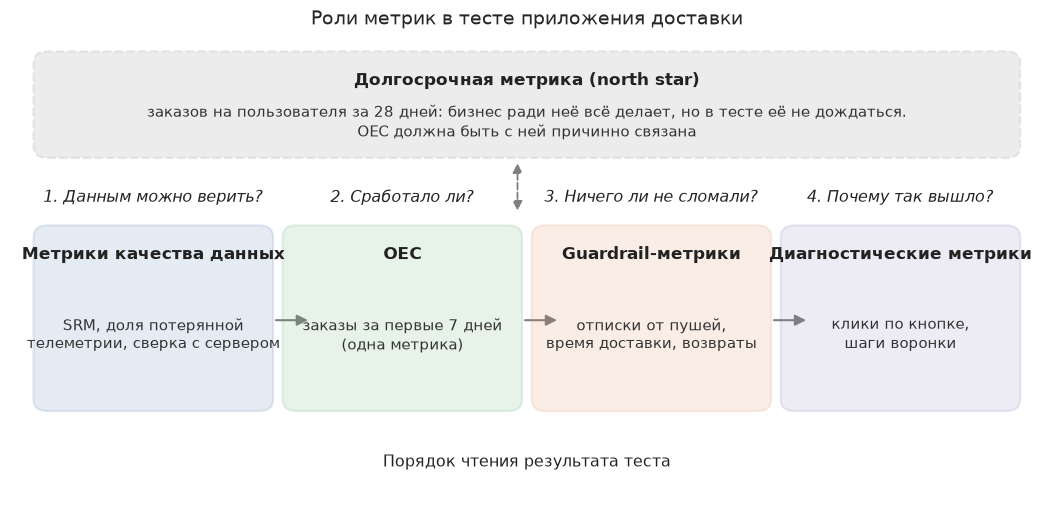

In [3]:
def draw_roles():
    fig, ax = plt.subplots(figsize=(11, 5.4))
    ax.set_xlim(0, 11)
    ax.set_ylim(0, 6)
    ax.axis('off')
    ax.grid(False)

    def box(x, y, w, h, title, body, color, dashed=False):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05,rounding_size=0.15', facecolor=color, edgecolor=GRAY if dashed else color,
                                    alpha=.14, linewidth=1.6, linestyle='--' if dashed else '-'))
        ax.text(x + w / 2, y + h - .32, title, ha='center', va='center', fontsize=12.5, fontweight='bold', color='#222222')
        ax.text(x + w / 2, y + h / 2 - .22, body, ha='center', va='center', fontsize=10.5, color='#333333', linespacing=1.35)

    box(.3, 4.5, 10.4, 1.25, 'Долгосрочная метрика (north star)', 'заказов на пользователя за 28 дней: бизнес ради неё всё делает, но в тесте её не дождаться.\nOEC должна быть с ней причинно связана', GRAY, dashed=True)
    steps = [
        (.3, 'Данным можно верить?', 'Метрики качества данных', 'SRM, доля потерянной\nтелеметрии, сверка с сервером', BLUE),
        (2.95, 'Сработало ли?', 'OEC', 'заказы за первые 7 дней\n(одна метрика)', GREEN),
        (5.6, 'Ничего ли не сломали?', 'Guardrail-метрики', 'отписки от пушей,\nвремя доставки, возвраты', ORANGE),
        (8.25, 'Почему так вышло?', 'Диагностические метрики', 'клики по кнопке,\nшаги воронки', PURPLE),
    ]
    for k, (x, question, title, body, color) in enumerate(steps):
        ax.text(x + 1.225, 3.95, f'{k + 1}. {question}', ha='center', va='center', fontsize=11.5, color='#222222', style='italic')
        box(x, 1.3, 2.45, 2.25, title, body, color)
        if k < 3:
            ax.add_patch(FancyArrowPatch((x + 2.5, 2.4), (x + 2.9, 2.4), arrowstyle='-|>', mutation_scale=16, color=GRAY, linewidth=1.5))
    ax.add_patch(FancyArrowPatch((5.4, 3.75), (5.4, 4.42), arrowstyle='<|-|>', mutation_scale=14, color=GRAY, linewidth=1.3, linestyle='--'))
    ax.text(5.5, .55, 'Порядок чтения результата теста', ha='center', fontsize=11.5, color='#222222')
    ax.set_title('Роли метрик в тесте приложения доставки', fontsize=14, pad=8)
    plt.tight_layout()
    plt.show()


draw_roles()

## Сначала проверь сплит: SRM

Первая строка порядка чтения — метрики качества данных, и главная из них проверяется раньше любых эффектов. **SRM (sample ratio mismatch)** — расхождение фактических долей групп с плановыми. Проверяется критерием хи-квадрат на согласие по числу пользователей в группах (из базового курса). Если SRM есть, сломано назначение в группы или сбор данных, и любой эффект может оказаться артефактом: результат не читаем, а ищем причину. Порог для этой проверки берут строже обычного (например, 0.001): её делают в каждом тесте, и ложная тревога тоже стоит денег.

In [4]:
n_control, n_test = 50_600, 49_400  # план 50/50
srm = st.chisquare([n_control, n_test])
print(f'Доля теста: {n_test / (n_control + n_test):.1%}, p-value χ²: {srm.pvalue:.1e}')

Доля теста: 49.4%, p-value χ²: 1.5e-04


Разница в 1.2 п.п. на глаз выглядит мелочью, но при ста тысячах пользователей случайно она почти не возникает. Типичные причины: бот-трафик, который фильтруется в одной группе иначе, падения клиента в новой версии, редиректы, теряющие часть пользователей, разная потеря телеметрии. Но и отсутствие SRM по пользователям ещё не гарантирует, что метрики сравнимы.

## Метрика-SRM: когда меняется набор наблюдений

С SRM на уровне пользователей мы уже знакомы: если доли групп не совпали с планом, тесту нельзя верить. Но у такого же сбоя есть **метрический двойник**. Пользователей в группах поровну, а набор событий, по которым считается метрика, разный. Тогда метрику использовать нельзя.

Классический пример из статьи Dmitriev и др.: в Microsoft на главной странице MSN ссылки начали открывать в новой вкладке. Время загрузки главной выросло на 8.32%. Откуда деградация от одной строчки JavaScript? Оказалось, что в контроле пользователь после перехода по ссылке возвращался кнопкой «назад», и главная перезагружалась. Такие перезагрузки быстрее первой загрузки из-за кэша. В тесте вкладка с главной оставалась открытой, перезагрузок не было, и быстрые загрузки из среднего пропали. Число загрузок главной в тесте было на 7.8% ниже.

Воспроизведём механизм на нашем кейсе. В тесте мы открываем карточку ресторана поверх главной: «назад» не перезагружает главную. Скорость самой главной не менялась совсем.

In [5]:
def simulate_plt(rng, n=20000):
    """Загрузки главной: первая (медленная) и повторные при возврате назад (быстрые, из кэша). Скорость в группах одинакова."""
    data = {}
    for arm, back_rate in (('контроль', 1.0), ('тест', 0.0)):
        first = rng.poisson(5, n)
        back = rng.poisson(back_rate, n)
        loads = first + back
        user_of_load = np.repeat(np.arange(n), loads)
        is_first = np.concatenate([np.r_[np.ones(f, bool), np.zeros(b, bool)] for f, b in zip(first, back)])
        seconds = np.where(is_first, rng.lognormal(np.log(2.0) - .125, .5, loads.sum()), rng.lognormal(np.log(1.0) - .125, .5, loads.sum()))
        data[arm] = dict(loads=loads, first=first, total=np.bincount(user_of_load, seconds, n), total_first=np.bincount(user_of_load, seconds * is_first, n))
    return data


def plt_effects(seed):
    data = simulate_plt(np.random.default_rng(seed))
    c, t = data['контроль'], data['тест']
    return (ratio_effect(c['total'], c['loads'], t['total'], t['loads']), rel_effect(c['loads'].astype(float), t['loads'].astype(float)),
            ratio_effect(c['total_first'], c['first'], t['total_first'], t['first']))


avg_all, loads_eff, avg_first = plt_effects(0)
print(f'Среднее время загрузки на одну загрузку: {pct(avg_all[0])} (SE {100 * avg_all[1]:.1f} п.п.)')
print(f'Число загрузок на пользователя:          {pct(loads_eff[0])} (SE {100 * loads_eff[1]:.1f} п.п.)')
print(f'Время только первых загрузок:            {pct(avg_first[0])} (SE {100 * avg_first[1]:.1f} п.п.)')
repeats = [plt_effects(seed) for seed in range(100, 110)]
print('\nРазброс по 10 повторам: среднее время на загрузку от {} до {}, время первых загрузок от {} до {}'.format(
    pct(min(r[0][0] for r in repeats)), pct(max(r[0][0] for r in repeats)), pct(min(r[2][0] for r in repeats)), pct(max(r[2][0] for r in repeats))))

Среднее время загрузки на одну загрузку: +9.0% (SE 0.3 п.п.)
Число загрузок на пользователя:          -16.3% (SE 0.4 п.п.)
Время только первых загрузок:            -0.1% (SE 0.2 п.п.)



Разброс по 10 повторам: среднее время на загрузку от +8.7% до +9.6%, время первых загрузок от -0.4% до +0.3%


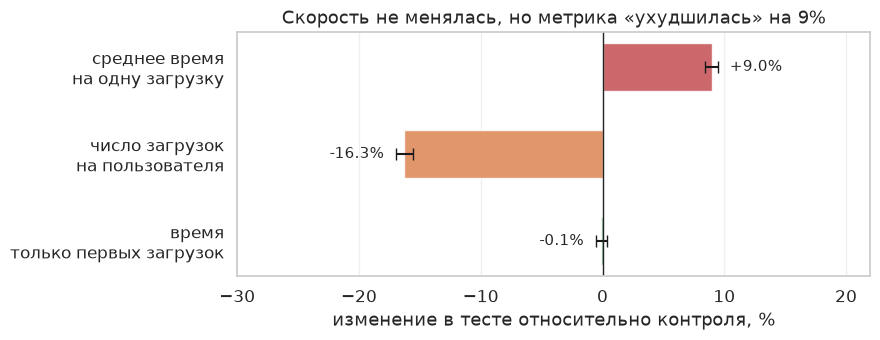

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
labels = ['среднее время\nна одну загрузку', 'число загрузок\nна пользователя', 'время\nтолько первых загрузок']
effects = [avg_all, loads_eff, avg_first]
colors = [RED, ORANGE, GREEN]
for k, ((effect, se), color) in enumerate(zip(effects, colors)):
    ax.barh(k, 100 * effect, xerr=196 * se, color=color, alpha=.85, height=.55, capsize=4)
    ax.text(100 * effect + np.sign(effect) * (196 * se + 1.0), k, pct(effect), va='center', ha='left' if effect > 0 else 'right', fontsize=11)
ax.axvline(0, color='#222222', linewidth=1)
ax.set_yticks(range(3))
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlim(-30, 22)
ax.set_xlabel('изменение в тесте относительно контроля, %')
ax.set_title('Скорость не менялась, но метрика «ухудшилась» на 9%')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

Метрика «среднее время на загрузку» показывает значимое ухудшение, хотя скорость не менялась: это следствие того, что из выборки исчезли быстрые повторные загрузки (число загрузок на пользователя упало на 16%). Если же сравнить только первые загрузки, разницы нет. На 10 повторах эффект на среднее время на загрузку лежит между +8.7% и +9.6%, а на первые загрузки между −0.4% и +0.3% (истинная разница равна нулю по построению).

Как заметить такое заранее:

* **Всегда смотреть на числитель и знаменатель ratio-метрики отдельно.** Статья советует считать оба как count-метрики и показывать вместе с отношением.
* **Проверять знаменатель так же, как SRM:** значимо ли отличается число событий (загрузок, показов, сессий) на пользователя. Значимое отличие означает, что набор наблюдений в группах разный и ratio сравнивать нельзя.
* **Если набор разный, искать подвыборку, которая сравнима по построению.** Здесь это первые загрузки.

Авторы статьи также советуют по умолчанию считать ratio-метрику как среднее отношений по пользователям, а не как отношение сумм: так знаменатель равен числу пользователей, которое контролируется экспериментом, и риск метрического SRM ниже, к тому же такую метрику проще анализировать и она устойчивее к выбросам. Но когда меняется набор наблюдений внутри самого пользователя, как в примере выше, это не спасает.

Причины метрического SRM бывают разные: изменение поведения (как здесь), разная потеря телеметрии, ошибка в разметке событий. Поэтому метрики с подозрением на SRM нельзя ни интерпретировать, ни использовать как guardrail.

## Закон Гудхарта: что бывает, если оптимизировать одну метрику

Метрика полезна, пока она остаётся индикатором. Как только её превращают в цель, её начинают двигать любыми способами, в том числе вредными. Это закон Гудхарта: когда мера становится целью, она перестаёт быть хорошей мерой.

**Вопрос.** Команда оптимизирует «среднее время в приложении». Тест нового экрана показал +9% к времени в приложении, а число заказов на пользователя не изменилось (p = 0.4). Запускаем?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Не как победу: рост времени без роста заказов ничего не доказывает, а может быть и признаком ухудшения (пользователь дольше ищет). Время может расти из-за того, что пользователю труднее найти нужное: он дольше листает и ищет. Нужны контрметрики: доля сессий с заказом, время до первого заказа, доля поисков без результата. Рост времени сам по себе нельзя считать победой, пока не проверено, что он идёт вместе с ростом долгосрочной ценности.

</details>

Допустим, команда пушей получила цель «вырастить число сессий на пользователя». Она тестирует 200 изменений. Среди них есть честные: они немного повышают и сессии, и заказы. И есть **накрутка**: более навязчивые пуши, которые дают много сессий, но раздражают людей, и заказов становится меньше. Мы закладываем в модель, что накрутка составляет 30% идей (это допущение, не факт про реальные команды).

Сравним две политики запуска:

* **A.** Запускаем всё, где сессии значимо выросли.
* **B.** Запускаем то же, но дополнительно требуем, чтобы заказы не просели сильнее, чем на 2%: нижняя граница 95% доверительного интервала по заказам должна быть выше −2%. Это guardrail.

Истинные эффекты нам известны, поэтому мы можем честно подсчитать, что получил бы продукт.

In [7]:
def goodhart_round(rng, n=200, gaming=.3, se_sessions=.6, se_orders=.6, margin=-2.0):
    """Одна «жизнь» команды: n идей, истинные эффекты в % на сессии и заказы, измеренные с шумом."""
    is_gaming = rng.random(n) < gaming
    sessions = np.where(is_gaming, rng.normal(2.0, 1.0, n), rng.normal(.5, 1.0, n))
    orders = np.where(is_gaming, rng.normal(-1.2, .6, n), .6 * sessions + rng.normal(0, .5, n))
    s_hat = sessions + rng.normal(0, se_sessions, n)
    o_hat = orders + rng.normal(0, se_orders, n)
    ship_a = s_hat / se_sessions > 1.96
    ship_b = ship_a & (o_hat - 1.96 * se_orders > margin)
    return {'policy': ['A: только сессии', 'B: сессии + guardrail'],
            'shipped': [ship_a.sum(), ship_b.sum()],
            'gaming_shipped': [(ship_a & is_gaming).sum(), (ship_b & is_gaming).sum()],
            'sessions': [sessions[ship_a].sum(), sessions[ship_b].sum()],
            'orders': [orders[ship_a].sum(), orders[ship_b].sum()]}


rounds = [goodhart_round(np.random.default_rng(seed)) for seed in range(500)]
gh = pd.DataFrame([{'policy': r['policy'][k], **{key: r[key][k] for key in ('shipped', 'gaming_shipped', 'sessions', 'orders')}} for r in rounds for k in (0, 1)])
summary = gh.groupby('policy').agg(shipped=('shipped', 'mean'), gaming_shipped=('gaming_shipped', 'mean'),
                                   sessions=('sessions', 'mean'), orders_mean=('orders', 'mean'), orders_p10=('orders', lambda x: x.quantile(.1)),
                                   orders_p90=('orders', lambda x: x.quantile(.9)))
summary.columns = ['запущено идей', 'из них накрутка', 'Σ эффект на сессии, %', 'Σ эффект на заказы, % (среднее)', 'то же, 10-й перцентиль', 'то же, 90-й перцентиль']
print(summary.round(1).to_string())

                       запущено идей  из них накрутка  Σ эффект на сессии, %  Σ эффект на заказы, % (среднее)  то же, 10-й перцентиль  то же, 90-й перцентиль
policy                                                                                                                                                       
A: только сессии                84.9             45.4                  167.2                            -18.6                   -33.2                    -5.1
B: сессии + guardrail           53.4             14.9                   94.4                             25.2                    16.0                    33.9


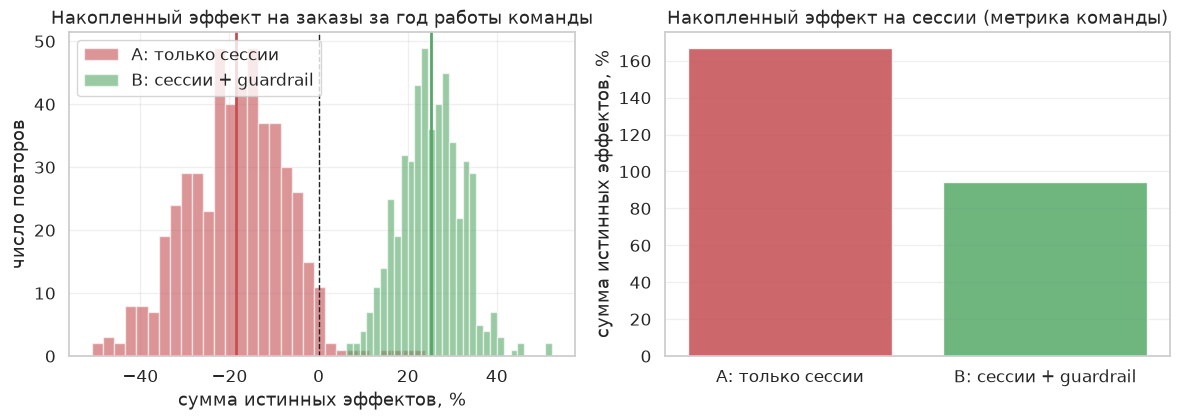

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
colors = {'A: только сессии': RED, 'B: сессии + guardrail': GREEN}
for name, color in colors.items():
    part = gh[gh.policy == name]
    axes[0].hist(part.orders, bins=30, color=color, alpha=.6, label=name)
    axes[0].axvline(part.orders.mean(), color=color, linewidth=2)
    axes[1].bar(name, part.sessions.mean(), color=color, alpha=.85)
axes[0].axvline(0, color='#222222', linewidth=1, linestyle='--')
axes[0].set_title('Накопленный эффект на заказы за год работы команды')
axes[0].set_xlabel('сумма истинных эффектов, %')
axes[0].set_ylabel('число повторов')
axes[0].legend(loc='upper left')
axes[1].set_title('Накопленный эффект на сессии (метрика команды)')
axes[1].set_ylabel('сумма истинных эффектов, %')
axes[1].grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

Политика A выигрывает по метрике, на которой её оценивают: сумма эффектов на сессии около +167 п.п. против +94 у политики B. Но платой за это становятся накрученные идеи: A запускает в среднем 45 из них (из 85 запущенных идей), и **заказы в сумме уходят в минус**: в среднем около −19 п.п., а даже 90-й перцентиль по повторам остаётся отрицательным (около −5). Политика B запускает 15 накруток и 38 честных идей и даёт около +25 п.п. по заказам (от +16 до +34 между 10-м и 90-м перцентилями). Guardrail отсекает почти всю накрутку, зато и сессий добавляется меньше: часть честных идей тоже не проходит проверку, потому что guardrail измеряется с шумом. Это обычная цена защиты, и платить её надо осознанно.

Правило отсюда простое: **у метрики-цели всегда должна быть пара из guardrail-метрик, определённых до запуска.** Определять их после, когда мы уже видим данные, значит искать подходящий результат. Ещё лучше иметь **контрметрику**, которая ломается ровно тогда, когда метрику накручивают: для сессий это доля сессий, закончившихся заказом, или доля отписавшихся.

Эта модель игрушечная: доля накрутки, размеры эффектов и шум выбраны нами, и конкретные цифры нельзя переносить на ваш продукт. Но механизм настоящий: отбор по одной метрике собирает вместе и честные идеи, и те, что просто сильнее двигают метрику.

Guardrail-метрики защищают от накрутки, но у них есть цена, которую мы ещё не посчитали: каждая метрика в отчёте — это отдельная проверка гипотезы. Целевая, несколько guardrail, десяток диагностических и разрезы по сегментам — и вот у нас уже десятки проверок в одном тесте. Разберёмся, что происходит с ошибками, когда проверок много.

## Множественное тестирование: задачка про «экстрасенсов»

**Вопрос.** Это учебный пример, известный как **парадокс Райна**: он назван в честь парапсихолога Джозефа Бэнкса Райна (Joseph Banks Rhine), изучавшего экстрасенсорное восприятие. Настоящие опыты Райна были устроены сложнее, а числа ниже условные.

Каждый испытуемый должен угадать цвет 10 карт подряд, причём каждая карта с равной вероятностью оказывается одного из двух цветов. Исследователь считает, что случайно угадать 9 или 10 карт из десяти почти невозможно, поэтому такой результат будет свидетельством экстрасенсорных способностей.

Из тысячи испытуемых 12 человек угадали 9 карт из 10, а двое угадали все 10.

Исследователь хочет объявить 14 человек экстрасенсами и спрашивает вашего мнения. Что вы ему скажете и чего ждать от повторной проверки?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Четырнадцать «экстрасенсов» среди тысячи человек — ровно то, что даёт чистое угадывание, поэтому повторная проверка почти никого не подтвердит. Для одного человека вероятность угадать 9 или 10 карт из 10 около 1%, но людей тысяча, и случайно таких наберётся в среднем около 11. Порог «почти невозможно» был рассчитан на одну проверку, а проверок было тысяча. Отобранные по случайно высокому результату люди на втором этапе вернутся к обычному результату: это регрессия к среднему. Ровно так же ведут себя «значимые» метрики, найденные перебором двадцати метрик отчёта.

</details>

### Разбор

**1. Какова вероятность случайно угадать 9 или 10 карт из десяти?**

Пусть $X$ — число карт, угаданных одним человеком. Без экстрасенсорных способностей каждая карта угадывается с вероятностью $p = 0.5$, поэтому $X \sim \text{Bin}(n=10, p=0.5)$.

1. Вероятность угадать ровно $k$ карт: $P(X = k) = \binom{10}{k} (0.5)^{10}$.

2. Вероятность угадать **не менее 9 карт**: $P(X \geq 9) = P(X=9) + P(X=10)$.

3. Считаем:

   $P(X=9) = \binom{10}{9} (0.5)^{10} = \frac{10}{1024} \approx 0.00977$

   $P(X=10) = \binom{10}{10} (0.5)^{10} = \frac{1}{1024} \approx 0.00098$

   $P(X \geq 9) = \frac{11}{1024} \approx 0.0107$

То есть вероятность случайно угадать 9 или 10 карт из 10 составляет **примерно 1.07%**.

**2. Почему второй этап не подтвердил их способности?**

Вероятность 1% мала для одного человека, но испытуемых тысяча. Посчитаем, чего ждать от тысячи людей, которые просто угадывают.

Вероятность для одного человека:         0.01074
Ожидаем удачливых среди 1000:           10.7
Вероятность, что удачливых не будет:     2.0e-05
Вероятность хотя бы одного удачливого:   0.99998
Вероятность найти 14 и больше:             0.194
Ожидаем повторивших успех из 14:          0.15


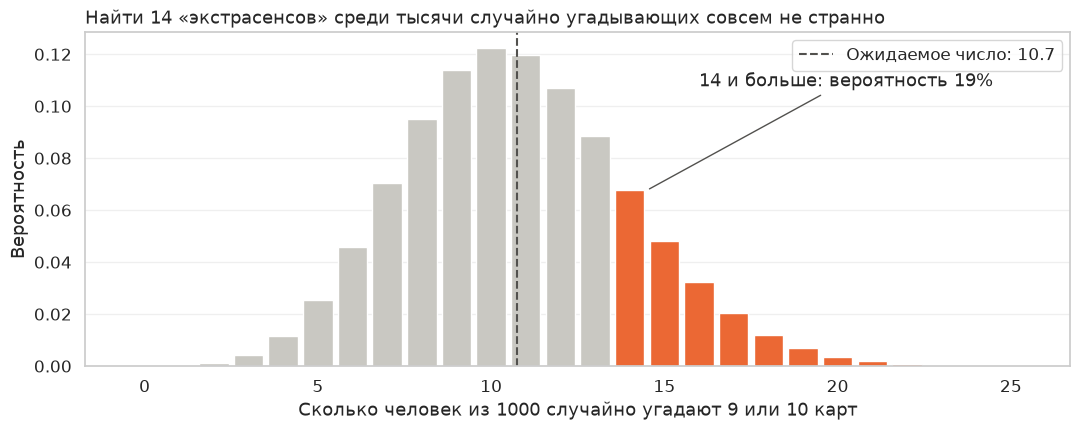

In [9]:
p_single = stats.binom.sf(8, 10, 0.5)  # P(X >= 9) = 11/1024
n_people = 1000
n_found = 14

expected_lucky = n_people * p_single
p_nobody = (1 - p_single) ** n_people
p_at_least_found = stats.binom.sf(n_found - 1, n_people, p_single)
expected_retest = n_found * p_single
p_any_retest = 1 - (1 - p_single) ** n_found

print(f"Вероятность для одного человека:         {p_single:.5f}")
print(f"Ожидаем удачливых среди {n_people}:           {expected_lucky:.1f}")
print(f"Вероятность, что удачливых не будет:     {p_nobody:.1e}")
print(f"Вероятность хотя бы одного удачливого:   {1 - p_nobody:.5f}")
print(f"Вероятность найти {n_found} и больше:             {p_at_least_found:.3f}")
print(f"Ожидаем повторивших успех из {n_found}:          {expected_retest:.2f}")

counts = np.arange(0, 26)
probabilities = stats.binom.pmf(counts, n_people, p_single)
colors = [NULL_COLOR if c >= n_found else '#c9c8c2' for c in counts]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(counts, probabilities, color=colors, width=0.85)
ax.axvline(expected_lucky, color=REFERENCE_COLOR, linestyle='--', linewidth=1.5,
           label=f'Ожидаемое число: {expected_lucky:.1f}')
ax.annotate(f'{n_found} и больше: вероятность {p_at_least_found:.0%}', xy=(n_found + 0.5, probabilities[n_found]),
            xytext=(n_found + 2, probabilities[n_found] + 0.04), arrowprops={'arrowstyle': '-', 'color': REFERENCE_COLOR})
ax.set_title('Найти 14 «экстрасенсов» среди тысячи случайно угадывающих совсем не странно', loc='left')
ax.set_xlabel('Сколько человек из 1000 случайно угадают 9 или 10 карт')
ax.set_ylabel('Вероятность')
ax.grid(axis='x', visible=False)
ax.legend()
plt.tight_layout()
plt.show()

Получается следующее:

* Чистая случайность даёт в среднем около 11 «экстрасенсов», а вероятность не найти ни одного составляет порядка $2 \cdot 10^{-5}$. Обнаружить таких людей почти гарантированно, и 14 найденных вполне укладываются в это ожидание.
* На втором этапе каждый из 14 снова проходит порог с вероятностью около 1%, то есть в среднем повторит успех лишь 0.15 человека. Этот возврат к обычному результату называется **регрессией к среднему**: мы отобрали людей по случайно высокому результату, и случайность второй раз не повторилась.

По учебной легенде, Райн сделал другой вывод: людям нельзя сообщать об их способностях, потому что от этого способности пропадают. Это хорошая иллюстрация того, как легко объяснить случайный шум содержательной историей.

## Фундаментальная проблема множественного тестирования

Это явление называется **проблемой множественных сравнений, или проблемой множественного тестирования (multiple testing problem)**.

При проведении статистического теста мы обычно устанавливаем уровень значимости $\alpha$, который ограничивает вероятность **ошибки первого рода (Type I error)**. Ошибка первого рода — это отклонение нулевой гипотезы, когда она на самом деле верна. Например, $\alpha = 0.05$ означает: если эффекта нет, тест ошибочно найдёт его примерно в 5% случаев.

Однако когда мы проводим **несколько тестов** на одних данных или в рамках одного исследования, вероятность совершить хотя бы одну ошибку первого рода **резко возрастает**.

Представьте, что мы проводим 100 независимых тестов и все нулевые гипотезы верны. Тогда **ожидаемое число ложных отклонений равно 5**, а **вероятность получить хотя бы один ложноположительный результат равна $1 - 0.95^{100} \approx 99.4\%$**. Почти гарантированно найдётся какой-то «значимый» результат просто по воле случая.

---
Рассмотрим конкретный пример.

Предположим, что мы аналитики в крупной IT-компании и проверяем 50 новых фич в мобильном приложении, для каждой фичи запускаем свой тест на своих пользователях. Мы моделируем A/A-тесты, то есть знаем, что **эффекта нет** у всех 50 фич и все 50 нулевых гипотез верны. Хотим понять, как часто мы получим ложноположительные результаты без какой-либо корректировки.

Для каждой фичи используем t-тест для сравнения средних контрольной и тестовой групп с уровнем значимости $\alpha = 0.05$. Для эмпирической оценки проведём 10 000 симуляций этого сценария.

В ходе симуляции рассчитаем две ключевые метрики:

*   **FWER (Family-Wise Error Rate), групповая вероятность ошибки первого рода**: вероятность того, что **хотя бы один из тестов** даст ложноположительный результат.
*   **FDR (False Discovery Rate), ожидаемая доля ложных открытий**: средняя доля ложных «открытий» среди всех сделанных «открытий», то есть отклонённых нулевых гипотез.

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 43/10000 [00:00<00:23, 429.46it/s]

  1%|          | 94/10000 [00:00<00:21, 469.32it/s]

  1%|▏         | 143/10000 [00:00<00:20, 476.97it/s]

  2%|▏         | 202/10000 [00:00<00:18, 520.86it/s]

  3%|▎         | 259/10000 [00:00<00:18, 537.90it/s]

... (167 outputs left out)

 99%|█████████▉| 9892/10000 [00:18<00:00, 552.87it/s]

 99%|█████████▉| 9949/10000 [00:18<00:00, 555.89it/s]

100%|██████████| 10000/10000 [00:18<00:00, 544.71it/s]

Эмпирический FWER для 50 гипотез при alpha=0.05: 0.9241
Эмпирический FDR для 50 гипотез при alpha=0.05: 0.9241
Теоретическое значение 1 - (1 - alpha)^m: 0.9231


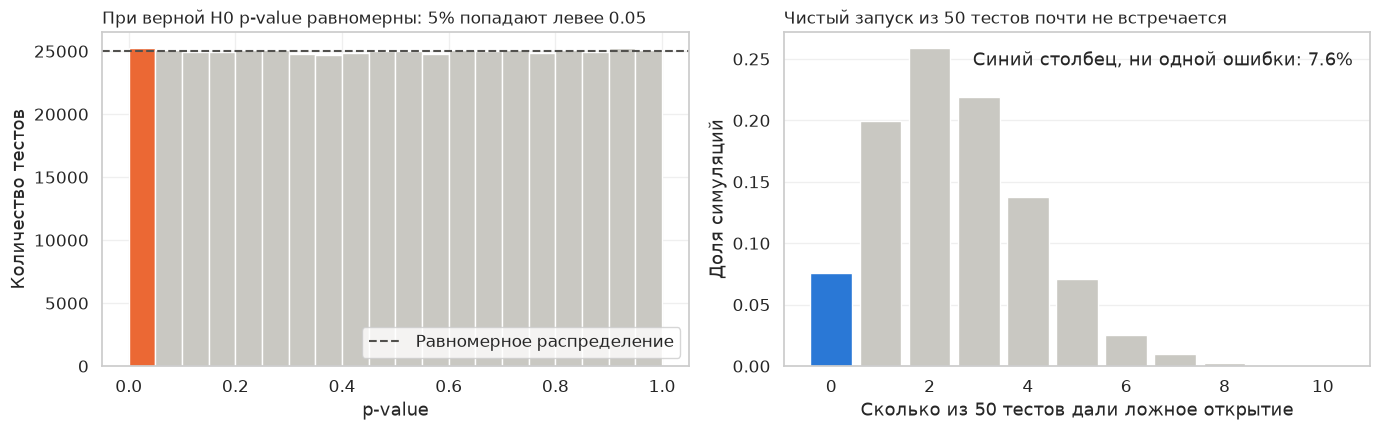

In [10]:
rng = np.random.default_rng(42)  # Для воспроизводимости результатов

# Параметры симуляции
num_hypotheses = 50       # Количество параллельных гипотез (фич)
alpha_level = 0.05        # Уровень значимости для каждого отдельного теста
num_simulations = 10_000  # Количество итераций симуляции для эмпирической оценки
group_size = 200          # Размер каждой группы (контрольной и тестовой)
mu = 0                    # Среднее значение для генерации данных (нет эффекта)
std = 1                   # Стандартное отклонение для генерации данных

all_pvalues = np.zeros((num_simulations, num_hypotheses))

for sim in tqdm(range(num_simulations)):
    # Каждая строка матрицы — один независимый A/A-тест
    control_group = rng.normal(mu, std, size=(num_hypotheses, group_size))
    treatment_group = rng.normal(mu, std, size=(num_hypotheses, group_size))
    all_pvalues[sim] = stats.ttest_ind(control_group, treatment_group, axis=1).pvalue

# В A/A-тесте все эффекты нулевые, поэтому каждое отклонение ложное: V = R
false_positives_V = np.sum(all_pvalues <= alpha_level, axis=1)
total_rejections_R = false_positives_V

# Эмпирическая оценка FWER: доля симуляций хотя бы с одним ложным открытием
empirical_fwer = np.mean(false_positives_V >= 1)
# Эмпирическая оценка FDR: среднее V/R, где при R = 0 доля считается равной 0
empirical_fdr = np.mean(false_positives_V / np.maximum(total_rejections_R, 1))

print(f"Эмпирический FWER для {num_hypotheses} гипотез при alpha={alpha_level}: {empirical_fwer:.4f}")
print(f"Эмпирический FDR для {num_hypotheses} гипотез при alpha={alpha_level}: {empirical_fdr:.4f}")
print(f"Теоретическое значение 1 - (1 - alpha)^m: {1 - (1 - alpha_level) ** num_hypotheses:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

bins = np.linspace(0, 1, 21)
heights, _, patches = axes[0].hist(all_pvalues.ravel(), bins=bins, color='#c9c8c2', edgecolor='white')
patches[0].set_facecolor(NULL_COLOR)
axes[0].axhline(heights.mean(), color=REFERENCE_COLOR, linestyle='--', linewidth=1.5, label='Равномерное распределение')
axes[0].set_title('При верной H0 p-value равномерны: 5% попадают левее 0.05', loc='left', fontsize=12)
axes[0].set_xlabel('p-value')
axes[0].set_ylabel('Количество тестов')
axes[0].legend(loc='lower right')

values, frequencies = np.unique(false_positives_V, return_counts=True)
axes[1].bar(values, frequencies / num_simulations, color='#c9c8c2', width=0.85)
axes[1].patches[0].set_facecolor(REAL_COLOR)
axes[1].text(0.97, 0.9, f'Синий столбец, ни одной ошибки: {frequencies[0] / num_simulations:.1%}', transform=axes[1].transAxes, ha='right')
axes[1].set_title('Чистый запуск из 50 тестов почти не встречается', loc='left', fontsize=12)
axes[1].set_xlabel('Сколько из 50 тестов дали ложное открытие')
axes[1].set_ylabel('Доля симуляций')
axes[1].grid(axis='x', visible=False)

plt.tight_layout()
plt.show()

## Формальное обоснование

Предположим, у нас есть $m$ проверяемых нулевых гипотез: $H_1, H_2, \ldots, H_m$. Результаты этих тестов можно классифицировать следующим образом:

|                   | Нулевая гипотеза верна ($H_0$) | Альтернативная гипотеза верна ($H_A$) | Всего                  |
| :---------------- | :----------------------------- | :---------------------------------- | :--------------------- |
| **Отклоняем $H_0$** | $V$ (ложноположительные)         | $S$ (истинноположительные)        | $R = V + S$ (все отклонённые) |
| **Не отклоняем $H_0$** | $U$ (истинноотрицательные)     | $T$ (ложноотрицательные)          | $m - R$                |
| **Всего**         | $m_0$ (истинные $H_0$)           | $m - m_0$ (истинные $H_A$)          | $m$ (общее число гипотез) |

Здесь:
*   $m$: общее количество тестируемых гипотез.
*   $m_0$: неизвестное количество истинных нулевых гипотез.
*   $V$: количество **ложноположительных результатов (ошибок первого рода)**, также называемых «ложными открытиями».
*   $S$: количество **истинноположительных результатов**, или «истинных открытий».
*   $R = V + S$: общее количество **отклонённых нулевых гипотез**, или «открытий».
*   $T$: количество **ложноотрицательных результатов (ошибок второго рода)**.
*   $U$: количество **истинноотрицательных результатов**.

**FWER (Family-Wise Error Rate)**

**FWER** — это вероятность того, что **хотя бы одна** из истинных нулевых гипотез будет ошибочно отклонена. Формально:
$$ \text{FWER} = P(V \geq 1) $$

Это самый строгий из распространённых критериев: он ограничивает шанс на любую ошибку первого рода во всём семействе тестов.

Предположим, что все $m$ нулевых гипотез истинны ($m_0 = m$), а тесты статистически **независимы**. Вероятность не совершить ошибку первого рода в одном тесте равна $1 - \alpha$, поэтому вероятность не совершить ни одной такой ошибки равна произведению:
$$ P(V=0) = (1-\alpha)^m $$
Следовательно, вероятность совершить хотя бы одну ошибку первого рода равна:
$$ \text{FWER} = 1 - P(V=0) = \mathbf{1 - (1-\alpha)^m} $$

Когда произведение $m\alpha$ мало, работает линейное приближение:
$$ 1 - (1-\alpha)^m \approx m\alpha $$
Для любых $m$ величина $m\alpha$ остаётся верхней границей для FWER, но при большом числе тестов эта граница бесполезна: при $m = 50$ и $\alpha = 0.05$ она равна 2.5, а реальный FWER составляет около 0.92.

Различают два вида контроля. **Слабый контроль** гарантирует $\text{FWER} \le \alpha$ только тогда, когда верны все нулевые гипотезы. **Сильный контроль** гарантирует это при любом наборе истинных и ложных гипотез. На практике нужен именно сильный контроль, потому что мы не знаем, какие гипотезы верны. Все FWER-поправки из этой встречи дают сильный контроль.

**FDR (False Discovery Rate)**

**FDR** — это ожидаемая доля ложных открытий среди всех сделанных открытий. Формально:
$$ \text{FDR} = E\left[\frac{V}{R}\right] $$
Если $R=0$, доля $V/R$ по определению равна 0. Поэтому более точная запись:
$$ \text{FDR} = E\left[\frac{V}{\max(R,1)}\right] $$
FWER ограничивает вероятность хотя бы одного ложного открытия, а FDR ограничивает их среднюю *долю*. Поскольку $V / \max(R, 1) \le \mathbb{1}\{V \ge 1\}$, всегда выполняется $\text{FDR} \le \text{FWER}$. Поэтому FDR менее строгий, но более мощный подход. Его часто используют в разведочных исследованиях, где допустима некоторая доля ложных открытий, если истинных открытий заметно больше.

Когда **все $m$ нулевых гипотез истинны** ($m_0 = m$), любое отклонение ложно и $V = R$. Тогда
$$ \frac{V}{\max(R,1)} = \begin{cases} 1 & \text{если } R > 0 \\ 0 & \text{если } R = 0 \end{cases} $$
и математическое ожидание этой величины равно вероятности хотя бы одного отклонения:
$$ \text{FDR} = 1 \cdot P(R > 0) + 0 \cdot P(R = 0) = P(V \geq 1) = \text{FWER} $$
Это равенство не требует независимости. Если же тесты ещё и независимы, то:
$$ \mathbf{\text{FDR} = \text{FWER} = 1 - (1-\alpha)^m} $$

Как только появляются реальные эффекты, метрики расходятся: истинные открытия увеличивают знаменатель $R$ и снижают FDR, а на FWER они не влияют.

Посмотрим на это на графиках. Чтобы считать быстро, сразу сгенерируем z-статистики: у гипотез без эффекта $z \sim N(0, 1)$, а реальный эффект сдвигает $z$ на величину `effect`. Сдвиг 2.8 соответствует мощности 80% при $\alpha = 0.05$.

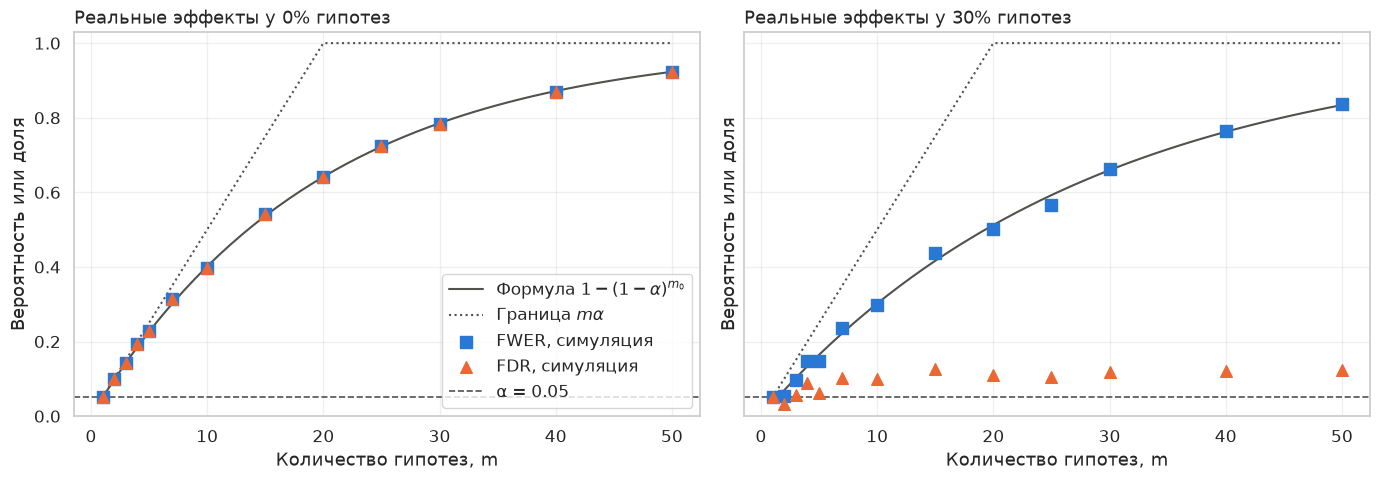

In [11]:
def simulate_pvalues(n_sims: int, m: int, n_real: int, effect: float, rng: np.random.Generator) -> np.ndarray:
    """Генерирует p-value двусторонних z-тестов: у первых n_real гипотез есть эффект, у остальных нет."""
    z = rng.standard_normal((n_sims, m))
    z[:, :n_real] += effect
    return 2 * stats.norm.sf(np.abs(z))


def error_rates(rejected: np.ndarray, n_real: int) -> dict:
    """Считает FWER, FDR и среднюю мощность по матрице решений (симуляции x гипотезы)."""
    V = rejected[:, n_real:].sum(axis=1)
    S = rejected[:, :n_real].sum(axis=1)
    R = V + S
    return {
        'FWER': np.mean(V >= 1),
        'FDR': np.mean(V / np.maximum(R, 1)),
        'Мощность': S.mean() / n_real if n_real > 0 else np.nan,
    }


def plot_fwer_fdr(ax, alpha: float = 0.05, share_real: float = 0.0, effect: float = 2.8, n_sims: int = 4000) -> None:
    """Рисует FWER и FDR без поправок в зависимости от числа гипотез m."""
    rng = np.random.default_rng(42)
    m_grid = np.array([1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40, 50])
    n_real_grid = np.round(share_real * m_grid).astype(int)

    rates = [error_rates(simulate_pvalues(n_sims, m, n_real, effect, rng) <= alpha, n_real)
             for m, n_real in zip(m_grid, n_real_grid)]

    fine_grid = np.arange(1, 51)
    ax.plot(fine_grid, 1 - (1 - alpha) ** (fine_grid * (1 - share_real)), color=REFERENCE_COLOR, linewidth=1.5,
            label='Формула $1 - (1-\\alpha)^{m_0}$')
    ax.plot(fine_grid, np.minimum(fine_grid * alpha, 1), color=REFERENCE_COLOR, linewidth=1.5, linestyle=':',
            label='Граница $m\\alpha$')
    ax.scatter(m_grid, [r['FWER'] for r in rates], s=70, color=REAL_COLOR, marker='s', zorder=3, label='FWER, симуляция')
    ax.scatter(m_grid, [r['FDR'] for r in rates], s=70, color=NULL_COLOR, marker='^', zorder=3, label='FDR, симуляция')
    ax.axhline(alpha, color=REFERENCE_COLOR, linestyle='--', linewidth=1.2, label=f'α = {alpha:.2f}')
    ax.set_ylim(0, 1.03)
    ax.set_xlabel('Количество гипотез, m')
    ax.set_ylabel('Вероятность или доля')
    ax.set_title(f'Реальные эффекты у {share_real:.0%} гипотез', loc='left')


fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
plot_fwer_fdr(axes[0], share_real=0.0)
plot_fwer_fdr(axes[1], share_real=0.3)
axes[0].legend(loc='lower right')
plt.tight_layout()
plt.show()

Слева все нулевые гипотезы верны: точки FWER и FDR совпадают и лежат на формуле. Справа 30% гипотез имеют реальный эффект: FWER продолжает расти, а FDR стабилизируется на низком уровне.

**Попробуйте сами.** Эта ячейка интерактивная: запустите её в Colab или Jupyter и подвигайте ползунки. Попробуйте увеличить долю реальных эффектов или уменьшить силу эффекта: при слабых эффектах истинных открытий мало, и FDR снова растёт.

In [12]:
def fwer_fdr_demo(alpha: float = 0.05, share_real: float = 0.3, effect: float = 2.8) -> None:
    fig, ax = plt.subplots(figsize=(10, 5))
    plot_fwer_fdr(ax, alpha, share_real, effect)
    ax.legend(loc='center right')
    plt.tight_layout()
    plt.show()


interact(fwer_fdr_demo,
         alpha=FloatSlider(value=0.05, min=0.01, max=0.2, step=0.01, description='α'),
         share_real=FloatSlider(value=0.3, min=0, max=0.9, step=0.1, description='Доля эффектов'),
         effect=FloatSlider(value=2.8, min=0.5, max=5, step=0.1, description='Сдвиг z'));

interactive(children=(FloatSlider(value=0.05, description='α', max=0.2, min=0.01, step=0.01), FloatSlider(valu…

## Критические последствия

Некорректный учёт множественного тестирования имеет серьёзные последствия в разных областях:

*   **Медицина: почему здесь важен FWER.** Здесь безопасность пациентов важнее всего. Если при сравнении нескольких доз, групп пациентов или конечных точек мы проверим много гипотез без поправки, случайный «положительный» эффект может выглядеть как доказанная эффективность. **Одного такого ложного открытия** достаточно, чтобы неэффективный препарат был одобрен и назначался вместо рабочего лечения. Поэтому регуляторы обычно требуют строгого контроля FWER по ключевым гипотезам.

*   **E-commerce: почему здесь часто берут FDR.** В электронной коммерции и рекомендациях число гипотез (дизайны кнопок, варианты рекомендаций, рекламные креативы) может достигать сотен и тысяч. Строгий контроль FWER здесь часто оказывается слишком консервативным и приводит к потере мощности, поэтому контролируют **FDR**. Если же не контролировать ничего, получаются **десятки или сотни ложноположительных «побед»**. Например, команда внедряет «новый алгоритм рекомендаций», который на самом деле не приносит пользы. Это приводит к **неэффективному расходованию ресурсов**, замедлению роста продукта и потере доверия к data-driven подходу.

*   **P-hacking и невоспроизводимость исследований.** Практика перебирать сравнения, метрики и срезы, пока не найдётся что-то «значимое», называется **p-hacking**. Она порождает **ложные корреляции** (spurious correlations), которые появляются просто из-за огромного числа возможных сравнений. Масштабный проект **Open Science Collaboration (2015)** пытался воспроизвести 100 психологических исследований, и статистически значимый результат удалось получить лишь примерно в 36% повторений. Множественные сравнения считаются одной из причин такого разрыва наряду с низкой мощностью исходных исследований и тем, что публикуются в основном значимые результаты.

Для решения проблемы разработаны разные корректирующие процедуры: поправка Бонферрони, метод Холма, метод Бенджамини–Хохберга, метод Бенджамини–Йекутиели и другие. Каждая из них имеет свои преимущества и ограничения в зависимости от требуемого уровня контроля ошибок и структуры зависимостей в данных.

## Методы контроля ошибок

### FWER

#### Поправка Бонферрони

**Формулировка**

Метод Бонферрони предлагает использовать для проверки каждой гипотезы уровень значимости $\alpha/m$, где $m$ — количество гипотез. Гипотеза отвергается, если её $p$-value удовлетворяет условию $p_i \le \alpha/m$.

**Доказательство**

Поправка гарантирует $\text{FWER} \le \alpha$. Это следует из неравенства Буля: вероятность того, что произойдёт хотя бы одно из конечного набора событий, не больше суммы вероятностей этих событий.

Пусть $I_0$ — множество истинных нулевых гипотез, их $m_0 \le m$ штук. Ложное открытие возможно только среди них, и для каждой такой гипотезы $P(p_i \le \alpha/m) \le \alpha/m$:

$$
\text{FWER} = P(V \ge 1) = P\left\{\bigcup _{i \in I_0}\left(p_{i}\leq {\frac {\alpha }{m}}\right)\right\}\leq \sum _{i \in I_0}P\left(p_{i}\leq {\frac {\alpha }{m}}\right)\leq m_0{\frac {\alpha }{m}}\leq\alpha
$$

Доказательство не использует независимость, поэтому поправка работает при **любой** зависимости между тестами.

**Замечание**

Метод Бонферрони прост в реализации, но консервативен. Его основной минус в том, что с ростом числа гипотез он сильно снижает мощность критерия, то есть увеличивает вероятность ошибки второго рода. Другие поправки уступают ему в простоте, но выигрывают в мощности.

In [13]:
def apply_bonferroni_correction(pvalues: np.ndarray, alpha: float = 0.05) -> np.ndarray:
    """Ручная реализация поправки Бонферрони."""
    return pvalues <= alpha / len(pvalues)

#### Метод Холма (поправка Холма — Бонферрони)

**Алгоритм**

1. Упорядочить $p$-value по возрастанию: $p_{(1)} \le p_{(2)} \le \dots \le p_{(m)}$.
2. Последовательно проверять их, начиная с самого маленького:
   * Если $p_{(1)} \le \alpha/m$, отвергнуть $H_{(1)}$ и перейти к следующему значению. Иначе остановиться и не отвергать ни одну гипотезу.
   * Если $p_{(2)} \le \alpha/(m-1)$, отвергнуть $H_{(2)}$ и перейти к следующему значению. Иначе остановиться.
   * И так далее: на шаге $i$ порог равен $\alpha/(m-i+1)$.
3. На первом шаге $i$, где условие нарушено, остановиться: гипотезы $H_{(i)}, \dots, H_{(m)}$ не отвергаются.

Логика такая: если самую сильную гипотезу мы отвергли, осталось $m-1$ гипотеза, и поправка для них может быть чуть мягче.

**Замечание**

Процедура Холма обеспечивает $\text{FWER} \le \alpha$ при любой зависимости между тестами. Она **равномерно мощнее** метода Бонферрони: отвергает всё то же, что и Бонферрони, и иногда больше. Поэтому Бонферрони для принятия решений всегда можно заменить Холмом.

Более того, без дополнительных предположений о зависимости пороги Холма нельзя поднять, не потеряв гарантию $\text{FWER} \le \alpha$. Более мощные процедуры используют дополнительную информацию, например независимость тестов или логические связи между гипотезами.

In [14]:
def apply_holm_correction(pvalues: np.ndarray, alpha: float = 0.05) -> np.ndarray:
    """Ручная реализация поправки Холма — Бонферрони."""
    n = len(pvalues)
    sorted_indices = np.argsort(pvalues)
    sorted_pvalues = pvalues[sorted_indices]

    rejected = np.zeros(n, dtype=bool)
    for i, (p, idx) in enumerate(zip(sorted_pvalues, sorted_indices)):
        if p <= alpha / (n - i):
            rejected[idx] = True
        else:
            break  # процедура останавливается на первой неотвергнутой гипотезе

    return rejected

#### Метод Шидака

**Формулировка**

Уровень значимости для $m$ гипотез задаётся так: $\alpha_m = 1 - (1-\alpha)^{1/m}$. Гипотеза отвергается, если $p_i \le \alpha_m$.

**Обоснование**

Если тесты независимы, вероятность отсутствия ошибок первого рода во всех $m$ тестах составляет $(1-\alpha^*)^m$, где $\alpha^*$ — уровень значимости одного теста. Чтобы получить $\text{FWER} = \alpha$, нужно решить $1 - (1-\alpha^*)^m = \alpha$, откуда $\alpha^* = 1 - (1-\alpha)^{1/m}$.

Метод гарантирует $\text{FWER} \le \alpha$ при независимости и при некоторых видах положительной зависимости. В частности, неравенство Шидака выполняется для двусторонних z-тестов с совместно нормальными статистиками при любых корреляциях. При произвольной зависимости гарантии нет.

**Замечание**

Выигрыш по сравнению с Бонферрони почти незаметен: при $m = 10$ и $\alpha = 0.05$ порог Шидака равен 0.00512, а порог Бонферрони равен 0.005. Поэтому на практике Шидака используют редко. Если независимость выполнена, можно применить пошаговый вариант **Холма–Шидака**: в `statsmodels` это `method='holm-sidak'`.

In [15]:
def apply_sidak_correction(pvalues: np.ndarray, alpha: float = 0.05) -> np.ndarray:
    """Ручная реализация поправки Шидака."""
    n = len(pvalues)
    sidak_alpha = 1 - (1 - alpha) ** (1 / n)
    return pvalues <= sidak_alpha

### FDR

#### Процедура Бенджамини–Хохберга

**Алгоритм**

1. Упорядочить $p$-value по возрастанию: $p_{(1)} \le p_{(2)} \le \dots \le p_{(m)}$.
2. Найти наибольшее $k$ такое, что $p_{(k)} \le \frac{k}{m}\alpha$.
3. Отклонить нулевые гипотезы $H_{(i)}$ для всех $i = 1, \dots, k$.

Геометрически это выглядит так: строим график $p_{(k)}$ от $k$, проводим через начало координат прямую с наклоном $\alpha/m$ и находим **самую правую** точку, которая не лежит выше прямой. Открытиями объявляем её и все точки слева, даже если некоторые из них лежат выше прямой.

Бенджамини и Хохберг доказали в 1995 году, что для независимых тестов процедура даёт $\text{FDR} \le \frac{m_0}{m}\alpha \le \alpha$. В 2001 году Бенджамини и Йекутиели показали, что этот результат сохраняется и при положительной зависимости особого вида (PRDS).

**Чем это отличается от Холма**

Холм идёт от маленьких p-value к большим и останавливается на первой неудаче, а BH идёт с другого конца и останавливается на первом успехе. Анимация показывает это на одних и тех же 12 p-value при $\alpha = 0.05$: чёрная линия показывает порог, а кольцо показывает текущую проверку.

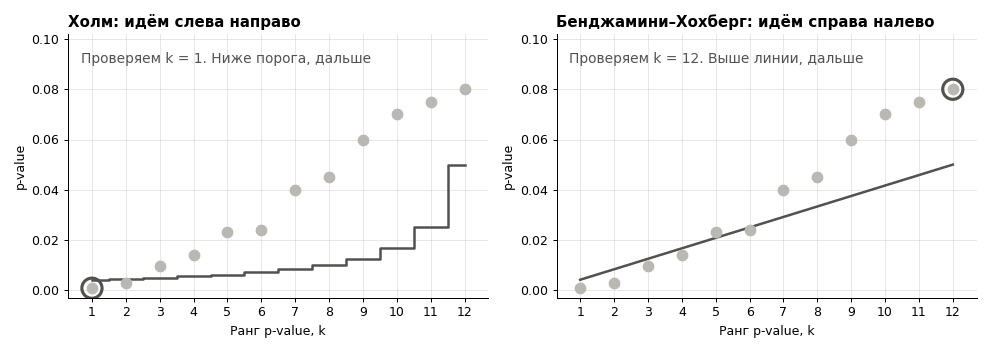

In [16]:
def apply_bh_correction(pvalues: np.ndarray, alpha: float = 0.05) -> np.ndarray:
    """Ручная реализация метода Бенджамини–Хохберга (FDR)."""
    n = len(pvalues)
    sorted_indices = np.argsort(pvalues)
    sorted_pvalues = pvalues[sorted_indices]

    # Вычисляем критические значения
    critical_values = (np.arange(n) + 1) * alpha / n

    # Находим наибольшее значимое p-value
    max_significant_idx = np.where(sorted_pvalues <= critical_values)[0]
    rejected = np.zeros(n, dtype=bool)
    if len(max_significant_idx) > 0:
        rejected[sorted_indices[:max_significant_idx[-1] + 1]] = True

    return rejected

Теперь сравним пороги на реалистичном примере: 50 гипотез, из них 10 с реальным эффектом. Чтобы разглядеть пороги, ось p-value обрезана сверху.

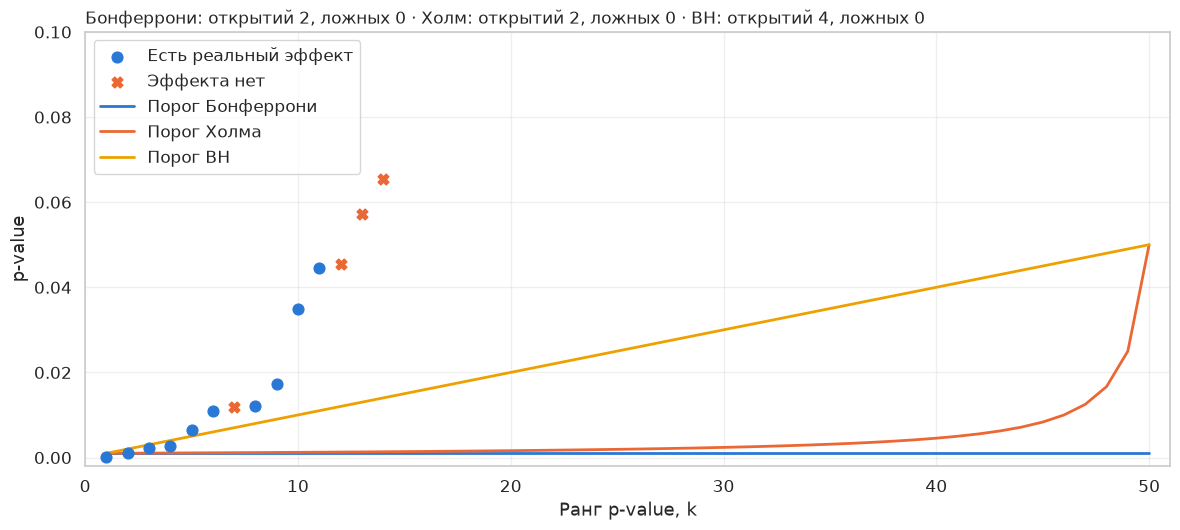

In [17]:
def plot_thresholds(m: int = 50, share_real: float = 0.2, effect: float = 3.0, alpha: float = 0.05, seed: int = 7) -> None:
    """Показывает отсортированные p-value и пороги Бонферрони, Холма и BH."""
    rng = np.random.default_rng(seed)
    n_real = int(round(share_real * m))
    pvalues = simulate_pvalues(1, m, n_real, effect, rng)[0]
    is_real = np.arange(m) < n_real

    order = np.argsort(pvalues)
    ranks = np.arange(1, m + 1)

    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.scatter(ranks[is_real[order]], pvalues[order][is_real[order]], s=60, color=REAL_COLOR, marker='o',
               zorder=3, label='Есть реальный эффект')
    ax.scatter(ranks[~is_real[order]], pvalues[order][~is_real[order]], s=60, color=NULL_COLOR, marker='X',
               zorder=3, label='Эффекта нет')
    ax.plot(ranks, np.full(m, alpha / m), color=METHOD_STYLE['Бонферрони'][0], linewidth=2, label='Порог Бонферрони')
    ax.plot(ranks, alpha / (m - ranks + 1), color=METHOD_STYLE['Холм'][0], linewidth=2, label='Порог Холма')
    ax.plot(ranks, ranks * alpha / m, color=METHOD_STYLE['BH'][0], linewidth=2, label='Порог BH')

    summary = []
    for name, correction in [('Бонферрони', apply_bonferroni_correction), ('Холм', apply_holm_correction),
                             ('BH', apply_bh_correction)]:
        rejected = correction(pvalues, alpha)
        summary.append(f'{name}: открытий {rejected.sum()}, ложных {(rejected & ~is_real).sum()}')

    ax.set_ylim(-0.02 * alpha * 2, alpha * 2)
    ax.set_xlim(0, m + 1)
    ax.set_title(' · '.join(summary), loc='left', fontsize=12)
    ax.set_xlabel('Ранг p-value, k')
    ax.set_ylabel('p-value')
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


plot_thresholds()

**Попробуйте сами.** Ползунки меняют число гипотез, долю реальных эффектов и их силу. Значение `seed` генерирует новый набор данных. Обратите внимание, что порог BH растёт с $k$: чем больше сильных сигналов, тем мягче он становится. Пороги Бонферрони и Холма такого преимущества почти не получают.

In [18]:
interact(plot_thresholds,
         m=IntSlider(value=50, min=10, max=200, step=10, description='m'),
         share_real=FloatSlider(value=0.2, min=0, max=0.8, step=0.05, description='Доля эффектов'),
         effect=FloatSlider(value=3.0, min=1, max=5, step=0.25, description='Сдвиг z'),
         alpha=FloatSlider(value=0.05, min=0.01, max=0.2, step=0.01, description='α'),
         seed=IntSlider(value=7, min=1, max=50, description='seed'));

interactive(children=(IntSlider(value=50, description='m', max=200, min=10, step=10), FloatSlider(value=0.2, d…

#### Метод Бенджамини–Йекутиели (BY)

**Формулировка**

Процедура Бенджамини–Йекутиели (Benjamini–Yekutieli, BY) контролирует FDR при **произвольной** зависимости между тестовыми статистиками. Она работает как BH, но с более строгим порогом: ищем наибольшее $k$ такое, что $p_{(k)} \le \frac{k}{m \cdot c(m)}\alpha$, где

$$ c(m) = \sum_{i=1}^{m} \frac{1}{i} \approx \ln(m) + \gamma + \frac{1}{2m}, \quad \gamma \approx 0.5772 $$

Здесь $c(m)$ — гармоническое число, а $\gamma$ — постоянная Эйлера–Маскерони. Если подставить $c(m) = 1$, получится обычная процедура BH.

BY универсальнее BH, потому что не требует независимости или положительной зависимости. Плата за это — потеря мощности: при $m = 50$ все пороги строже порогов BH примерно в 4.5 раза.

In [19]:
def apply_by_correction(pvalues: np.ndarray, alpha: float = 0.05) -> np.ndarray:
    """Ручная реализация метода Бенджамини–Йекутиели (BY)."""
    n = len(pvalues)
    c_n = np.sum(1 / np.arange(1, n + 1))  # Гармоническое число

    sorted_indices = np.argsort(pvalues)
    sorted_pvalues = pvalues[sorted_indices]

    # Вычисляем критические значения BY
    critical_values = (np.arange(n) + 1) * alpha / (n * c_n)

    # Находим наибольшее значимое p-value
    max_significant_idx = np.where(sorted_pvalues <= critical_values)[0]
    rejected = np.zeros(n, dtype=bool)
    if len(max_significant_idx) > 0:
        rejected[sorted_indices[:max_significant_idx[-1] + 1]] = True

    return rejected

### Проверка ручных реализаций

Сверим наши функции с библиотекой `statsmodels` на случайных наборах p-value. Выбор с возвращением нужен, чтобы в наборы попадали одинаковые значения: на них реализации чаще всего расходятся.

In [20]:
CORRECTIONS = {
    'Бонферрони': apply_bonferroni_correction,
    'Холм': apply_holm_correction,
    'Шидак': apply_sidak_correction,
    'BH': apply_bh_correction,
    'BY': apply_by_correction,
}
STATSMODELS_NAMES = {'Бонферрони': 'bonferroni', 'Холм': 'holm', 'Шидак': 'sidak', 'BH': 'fdr_bh', 'BY': 'fdr_by'}

rng = np.random.default_rng(42)
for name, correction in CORRECTIONS.items():
    for _ in range(300):
        pvalues = rng.choice(rng.beta(0.3, 2, size=20), size=rng.integers(2, 40), replace=True)
        alpha = rng.choice([0.01, 0.05, 0.1])
        assert np.array_equal(correction(pvalues, alpha), multipletests(pvalues, alpha, STATSMODELS_NAMES[name])[0]), name

print('Все ручные реализации совпали со statsmodels')

Все ручные реализации совпали со statsmodels


### Скорректированные p-value

На практике вместо изменения порога часто корректируют сами p-value. Скорректированное p-value сравнивается с исходным $\alpha$: гипотеза отвергается, если оно не больше $\alpha$. Такой подход удобнее для отчётов, потому что решение можно принять сразу для любого $\alpha$. Функция `multipletests` возвращает эти значения вторым элементом результата.

In [21]:
example_pvalues = np.array([0.001, 0.008, 0.012, 0.041, 0.074, 0.28])

adjusted = pd.DataFrame({'Исходное p-value': example_pvalues})
for name in ['Бонферрони', 'Холм', 'BH', 'BY']:
    adjusted[name] = multipletests(example_pvalues, method=STATSMODELS_NAMES[name])[1]

adjusted.round(3)

,Исходное p-value,Бонферрони,Холм,BH,BY
0,0.001,0.006,0.006,0.006,0.015
1,0.008,0.048,0.040,0.024,0.059
2,0.012,0.072,0.048,0.024,0.059
3,0.041,0.246,0.123,0.062,0.151
4,0.074,0.444,0.148,0.089,0.218
5,0.280,1.000,0.280,0.280,0.686


### Что в итоге использовать?

Для начала разберёмся с метрикой: как выбрать между FWER и FDR? Единственного правильного ответа нет, всё зависит от конкретного кейса.

* Если гипотез много и **хочется выбрать наиболее интересные** для дальнейшего анализа, можно опираться на **FDR**: так мы пропустим меньше реальных эффектов, а отдельная ложная находка обойдётся недорого.

* Если гипотез немного и фича **может сильно повлиять на ключевые метрики** (например, на деньги), особенно в отрицательную сторону, надёжнее использовать **FWER**, потому что он строже ограничивает ошибки первого рода.

Перед выбором поправки нужно определить **семейство гипотез**, то есть набор проверок, внутри которого мы считаем ошибки. Обычно это сравнения одного эксперимента, по которым принимается одно решение. Семейство фиксируется до запуска, иначе его можно незаметно подогнать под нужный результат.

Выбор метода можно сформулировать строже:

| Метод | Контролирует | Требования к зависимости | Когда использовать |
| :--- | :--- | :--- | :--- |
| Бонферрони | FWER | Нет | Для расчёта размера выборки и быстрой оценки при небольшом числе сравнений |
| Холм | FWER | Нет | Выбор по умолчанию для FWER |
| Шидак | FWER | Независимость или положительная зависимость | Редко, потому что выигрыш почти незаметен |
| Бенджамини–Хохберг | FDR | Независимость или PRDS | Выбор по умолчанию для FDR |
| Бенджамини–Йекутиели | FDR | Нет | Когда зависимость между тестами может быть отрицательной или неизвестна |

Для типовых схем сравнений есть специальные критерии, которые учитывают зависимость и поэтому мощнее универсальных поправок. Сравнения всех групп с одной контрольной выполняет **тест Даннета** (`scipy.stats.dunnett`), а сравнения всех пар групп выполняет **тест Тьюки** (`scipy.stats.tukey_hsd`).

### Симуляция

Сначала повторим частый сценарий: 5 групп без каких-либо эффектов и попарное сравнение всех со всеми, всего 10 тестов. Эти тесты зависимы, потому что каждая группа участвует сразу в четырёх сравнениях. Здесь FWER совпадает с FDR, потому что все нулевые гипотезы верны.

Симуляция экспериментов:   0%|          | 0/4000 [00:00<?, ?it/s]

Симуляция экспериментов:   0%|          | 10/4000 [00:00<00:42, 94.54it/s]

Симуляция экспериментов:   1%|          | 21/4000 [00:00<00:39, 100.03it/s]

Симуляция экспериментов:   1%|          | 32/4000 [00:00<00:38, 101.75it/s]

Симуляция экспериментов:   1%|          | 44/4000 [00:00<00:37, 105.16it/s]

Симуляция экспериментов:   1%|▏         | 55/4000 [00:00<00:38, 103.15it/s]

... (355 outputs left out)

Симуляция экспериментов:  99%|█████████▉| 3978/4000 [00:39<00:00, 102.67it/s]

Симуляция экспериментов: 100%|█████████▉| 3989/4000 [00:39<00:00, 102.84it/s]

Симуляция экспериментов: 100%|██████████| 4000/4000 [00:39<00:00, 103.68it/s]

Симуляция экспериментов: 100%|██████████| 4000/4000 [00:39<00:00, 101.68it/s]

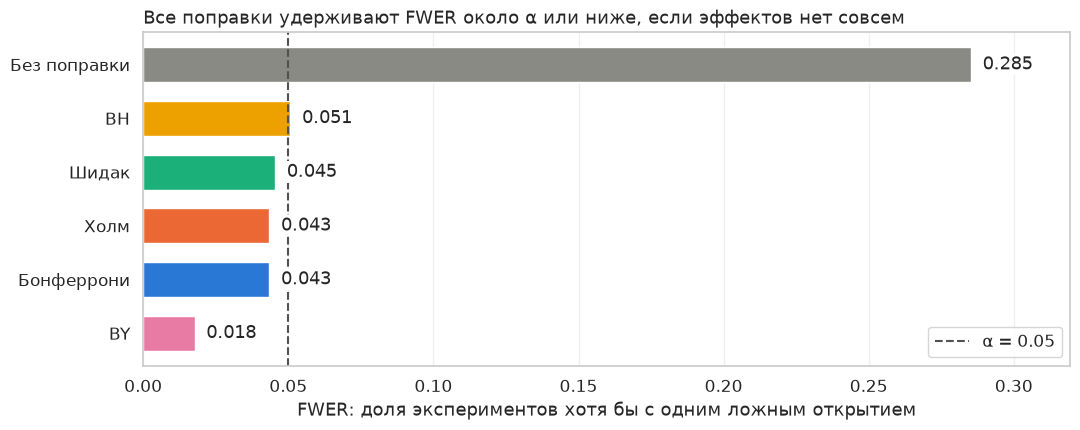

Формула для независимых тестов дала бы 0.401, симуляция без поправки: 0.285


In [22]:
def pairwise_pvalues(data: np.ndarray) -> np.ndarray:
    """Выполняет попарные t-тесты Уэлча между строками матрицы data."""
    return np.array([stats.ttest_ind(a, b, equal_var=False).pvalue for a, b in itertools.combinations(data, 2)])


def simulate_pairwise_fwer(n_runs: int, n_groups: int, n_per_group: int, alpha: float, seed: int) -> pd.Series:
    """Оценивает FWER при попарных сравнениях групп без эффекта."""
    rng = np.random.default_rng(seed)
    any_rejected = {name: 0 for name in ['Без поправки', *CORRECTIONS]}

    for _ in tqdm(range(n_runs), desc="Симуляция экспериментов"):
        pvalues = pairwise_pvalues(rng.normal(size=(n_groups, n_per_group)))
        any_rejected['Без поправки'] += np.any(pvalues <= alpha)
        for name, correction in CORRECTIONS.items():
            any_rejected[name] += np.any(correction(pvalues, alpha))

    return pd.Series(any_rejected) / n_runs


pairwise_fwer = simulate_pairwise_fwer(n_runs=4000, n_groups=5, n_per_group=100, alpha=0.05, seed=42)

fig, ax = plt.subplots(figsize=(11, 4.5))
ordered = pairwise_fwer.sort_values()
ax.barh(ordered.index, ordered.values, color=[METHOD_STYLE[name][0] for name in ordered.index], height=0.65)
for position, value in enumerate(ordered.values):
    ax.text(value + 0.004, position, f'{value:.3f}', va='center', bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})
ax.axvline(0.05, color=REFERENCE_COLOR, linestyle='--', linewidth=1.5, label='α = 0.05')
ax.set_xlim(0, ordered.max() * 1.12)
ax.set_title('Все поправки удерживают FWER около α или ниже, если эффектов нет совсем', loc='left')
ax.set_xlabel('FWER: доля экспериментов хотя бы с одним ложным открытием')
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f"Формула для независимых тестов дала бы {1 - 0.95 ** 10:.3f}, симуляция без поправки: {pairwise_fwer['Без поправки']:.3f}")

FWER без поправки здесь ниже, чем даёт формула для независимых тестов: положительная зависимость делает ложные срабатывания «кучнее».

Но сценарий без единого эффекта не показывает разницу между методами: здесь FDR совпадает с FWER, поэтому BH выглядит как метод контроля FWER. Настоящая разница видна, когда часть эффектов реальна. Возьмём 20 независимых гипотез и будем менять долю реальных эффектов.

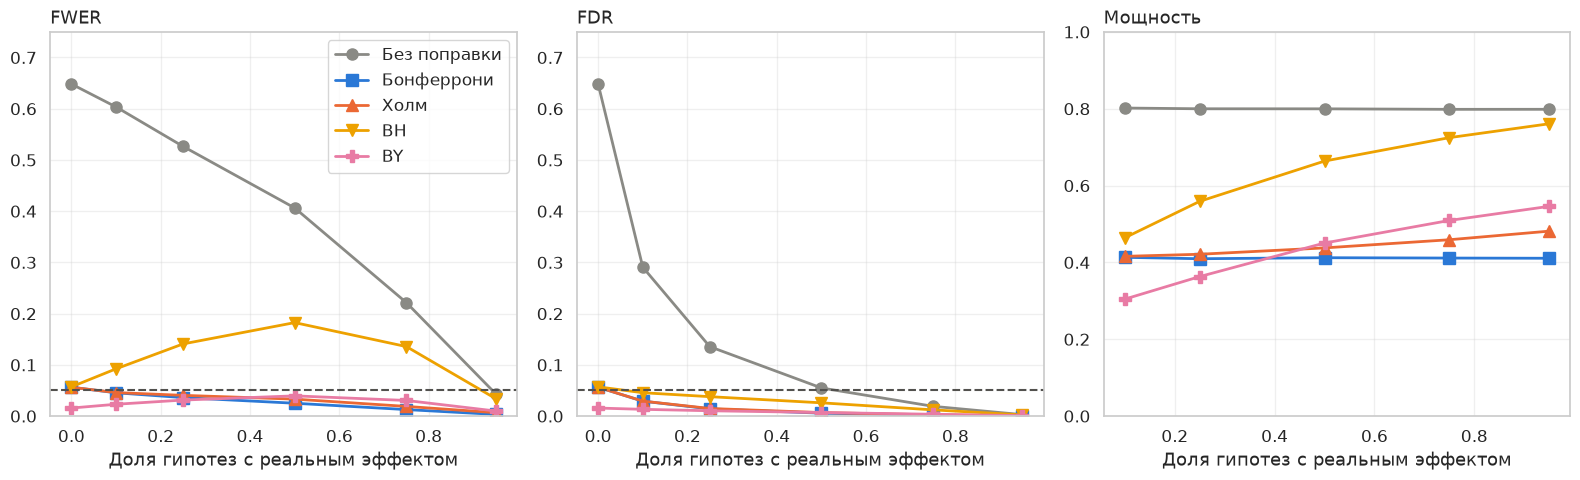

,FWER,FDR,Мощность
Метод,,,
Без поправки,0.526,0.135,0.800
Бонферрони,0.036,0.014,0.409
Холм,0.040,0.015,0.421
BH,0.141,0.038,0.559
BY,0.031,0.010,0.363


In [23]:
def compare_methods(m: int = 20, effect: float = 2.8, alpha: float = 0.05, n_sims: int = 5000, seed: int = 42) -> pd.DataFrame:
    """Считает FWER, FDR и мощность методов при разной доле реальных эффектов."""
    rng = np.random.default_rng(seed)
    rows = []
    for n_real in [0, 2, 5, 10, 15, 19]:
        pvalues = simulate_pvalues(n_sims, m, n_real, effect, rng)
        rows.append({'Метод': 'Без поправки', 'Доля эффектов': n_real / m, **error_rates(pvalues <= alpha, n_real)})
        for name in ['Бонферрони', 'Холм', 'BH', 'BY']:
            rejected = np.apply_along_axis(CORRECTIONS[name], 1, pvalues, alpha)
            rows.append({'Метод': name, 'Доля эффектов': n_real / m, **error_rates(rejected, n_real)})
    return pd.DataFrame(rows)


comparison = compare_methods()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric in zip(axes, ['FWER', 'FDR', 'Мощность']):
    for name, part in comparison.groupby('Метод', sort=False):
        color, marker = METHOD_STYLE[name]
        ax.plot(part['Доля эффектов'], part[metric], color=color, marker=marker, markersize=8, linewidth=2, label=name)
    if metric != 'Мощность':
        ax.axhline(0.05, color=REFERENCE_COLOR, linestyle='--', linewidth=1.5)
    ax.set_title(metric, loc='left')
    ax.set_xlabel('Доля гипотез с реальным эффектом')
axes[0].legend(loc='upper right')
axes[0].set_ylim(0, 0.75)
axes[1].set_ylim(0, 0.75)
axes[2].set_ylim(0, 1)
plt.tight_layout()
plt.show()

comparison[comparison['Доля эффектов'] == 0.25].set_index('Метод').drop(columns='Доля эффектов').round(3)

Что видно на графиках:

* **FWER.** Бонферрони и Холм держатся ниже $\alpha$ при любой доле эффектов. BH превышает $\alpha$: при 25% эффектов его FWER равен примерно 0.14. Это не дефект, потому что BH обещает контроль другой величины.
* **FDR.** Все поправки удерживают его ниже $\alpha$. У BH при 25% эффектов FDR близок к теоретической границе $\frac{m_0}{m}\alpha = 0.0375$.
* **Мощность.** При 25% эффектов BH находит 56% реальных эффектов, Холм находит 42%, а Бонферрони 41%. Чем больше реальных эффектов, тем сильнее выигрыш BH. Холм мощнее Бонферрони, но заметно это только при большой доле эффектов.
* **Без поправки** мощность максимальна, но при 25% эффектов каждое седьмое открытие оказывается ложным, а FWER превышает 50%.

## Учёт поправок при дизайне эксперимента

Теперь поговорим о том, как учесть множественное тестирование на этапе дизайна эксперимента.

Обычно при планировании мы проверяем, что выбранный критерий обеспечивает нужные значения ошибок первого и второго рода. Для этого берут исторические данные целевых метрик, многократно делят пользователей на control и treatment с заранее рассчитанным размером выборки, считают p-value выбранным критерием и оценивают ошибку первого рода. Чтобы оценить ошибку второго рода, к treatment-группе добавляют эффект.

В нашем случае мы заранее знаем, сколько будет тестовых групп и, следовательно, сколько гипотез мы проверим. Поэтому шаги такие:

1. Выбрать метод контроля ошибки первого рода: FWER, FDR или другой.
2. По аналогии с обычным экспериментом взять данные по интересующей нас метрике за предыдущий период.
3. Оценить размер выборки, необходимый для детекции заданного эффекта.
4. Разделить пользователей на группы и проверить на симуляции контроль выбранной метрики.
5. При необходимости скорректировать размер выборки с учётом желаемой мощности.

### Сетап эксперимента

Пусть у нас есть метрика с нормальным распределением: $\mu = 10$, $\sigma = 1$, $N = 1\,000\,000$ пользователей. Минимальный эффект, который мы хотим детектировать, равен 0.5%. В эксперименте будет 5 групп (1 контрольная и 4 тестовых), и мы сравниваем каждую группу с каждой.

В симуляции у всех четырёх тестовых групп одинаковый эффект. Значит, из 10 попарных сравнений 4 (контроль против теста) содержат реальный эффект, а 6 (тест против теста) не содержат.

#### Функции

In [24]:
def calculate_sample_size(
    effect_size: float,
    alpha: float = 0.05,
    power: float = 0.8,
    alternative: str = 'two-sided'
) -> int:
    """
    Рассчитывает необходимый размер одной группы для t-теста с равными группами.

    Parameters:
        effect_size (float): ожидаемый размер эффекта (Cohen's d).
        alpha (float): уровень значимости.
        power (float): требуемая мощность.
        alternative (str): 'two-sided' или 'larger'/'smaller' для одностороннего теста.

    Returns:
        int: необходимый размер выборки для каждой группы.
    """
    result = TTestIndPower().solve_power(effect_size=effect_size, power=power, alpha=alpha, alternative=alternative)
    return int(np.ceil(result))


def simulate_design(
    values: np.ndarray,
    effect: float,
    sample_size: int,
    n_groups: int,
    n_iter: int,
    alpha: float,
    rng: np.random.Generator
) -> pd.DataFrame:
    """
    Моделирует эксперимент с попарными сравнениями и оценивает ошибки разных поправок.

    Parameters:
        values (np.ndarray): исторические значения метрики.
        effect (float): множитель, который применяется к метрике в тестовых группах.
        sample_size (int): размер выборки для каждой группы.
        n_groups (int): число групп, первая из них контрольная.
        n_iter (int): количество итераций моделирования.
        alpha (float): уровень значимости.
        rng (np.random.Generator): генератор случайных чисел.

    Returns:
        pd.DataFrame: FWER, средняя ошибка II рода и вероятность хотя бы одного пропуска по каждому методу.
    """
    group_pairs = list(itertools.combinations(range(n_groups), 2))
    has_effect = np.array([first == 0 for first, _ in group_pairs])  # реальный эффект только в сравнениях с контролем

    methods = {'Без поправки': lambda p, a: p <= a, **{name: CORRECTIONS[name] for name in ['Бонферрони', 'Холм', 'BH']}}
    rejected = {name: np.zeros((n_iter, len(group_pairs)), dtype=bool) for name in methods}
    treatment_values = values * effect

    for iteration in tqdm(range(n_iter), desc=f'n = {sample_size}'):
        groups = [rng.choice(values, sample_size, replace=True)]
        groups += [rng.choice(treatment_values, sample_size, replace=True) for _ in range(n_groups - 1)]
        pvalues = np.array([stats.ttest_ind(groups[i], groups[j]).pvalue for i, j in group_pairs])
        for name, correction in methods.items():
            rejected[name][iteration] = correction(pvalues, alpha)

    rows = {}
    for name, decisions in rejected.items():
        rows[name] = {
            'FWER': np.mean(decisions[:, ~has_effect].any(axis=1)),
            'Ошибка II рода': 1 - decisions[:, has_effect].mean(),
            'P(хотя бы один пропуск)': np.mean(~decisions[:, has_effect].all(axis=1)),
        }
    return pd.DataFrame(rows).T

#### Симуляция

In [25]:
mu = 10
std = 1
effect = 1.005
population_size = 1_000_000
n_groups = 5

alpha = 0.05
beta = 0.2

rng = np.random.default_rng(42)
df = pd.DataFrame({"metric": rng.normal(mu, std, population_size)})

effect_size = (effect - 1) * mu / std  # эффект в стандартных отклонениях (Cohen's d)
n_comparisons = len(list(itertools.combinations(range(n_groups), 2)))
n_real_comparisons = n_groups - 1

Рассчитаем минимальный объём выборки, необходимый для детекции заданного эффекта без учёта множественности.

In [26]:
n_base = calculate_sample_size(effect_size, alpha=alpha, power=1 - beta)
print(f"Для равных групп необходимо по {n_base} участников в каждой группе.")

Для равных групп необходимо по 6281 участников в каждой группе.


Получаем, что для детекции эффекта в 0.5% на одну группу необходимо примерно 6.3 тыс. объектов. Посмотрим, что будет с ошибками при таком размере групп.

In [27]:
base_errors = simulate_design(df["metric"].values, effect, n_base, n_groups, n_iter=2000, alpha=alpha, rng=rng)
base_errors.round(3)

n = 6281:   0%|          | 0/2000 [00:00<?, ?it/s]

n = 6281:   0%|          | 8/2000 [00:00<00:25, 78.84it/s]

n = 6281:   1%|          | 17/2000 [00:00<00:23, 84.76it/s]

n = 6281:   1%|▏         | 27/2000 [00:00<00:21, 91.23it/s]

n = 6281:   2%|▏         | 37/2000 [00:00<00:21, 89.85it/s]

n = 6281:   2%|▏         | 46/2000 [00:00<00:22, 88.14it/s]

... (214 outputs left out)

n = 6281:  99%|█████████▉| 1986/2000 [00:23<00:00, 88.33it/s]

n = 6281: 100%|█████████▉| 1995/2000 [00:24<00:00, 88.27it/s]

n = 6281: 100%|██████████| 2000/2000 [00:24<00:00, 82.87it/s]

,FWER,Ошибка II рода,P(хотя бы один пропуск)
Без поправки,0.208,0.213,0.456
Бонферрони,0.026,0.519,0.822
Холм,0.033,0.497,0.785
BH,0.089,0.387,0.630


FWER здесь считается по шести сравнениям без реального эффекта. Что мы видим:

1. Без поправки FWER вырос примерно до 0.2. Бонферрони и Холм удерживают его ниже 0.05, а значение около 0.03 соответствует границе $\frac{m_0}{m}\alpha$ для 6 истинных нулевых гипотез из 10. BH превышает 0.05, потому что гарантирует только контроль FDR.
2. Поправки ожидаемо снижают мощность. Ошибка II рода вырастает с 0.2 примерно до 0.4 у BH и до 0.5 у методов контроля FWER.

Но при возможности мы можем вернуть ошибку II рода к нужному значению.

Уменьшить ошибку второго рода можно, увеличив размер выборки. Это следует из формулы размера одной группы для сравнения двух средних:

$$
N = \frac{2\sigma^2 \left( \Phi^{-1}_{1 - \alpha/2} + \Phi^{-1}_{1 - \beta} \right)^2}{\text{mde}^2}
$$

Поправка фактически уменьшает $\alpha$, поэтому в формулу можно подставить скорректированный уровень значимости.

[Существуют](https://link.springer.com/article/10.1007/s10732-020-09454-w) следующие подходы к коррекции размера выборки:

1. **Худший случай.** Рассчитываем размер выборки так, чтобы нужную мощность имел тест с самым строгим уровнем значимости. Самый строгий уровень даёт поправка Бонферрони: $\alpha_i = \alpha / m$. Это гарантирует заданную мощность каждого сравнения. Сам анализ всё равно стоит проводить методом Холма: он отвергает не меньше гипотез.

2. **Средняя или медианная мощность.** Метод Холма проверяет гипотезы с разными порогами от $\alpha/m$ до $\alpha$, поэтому можно поддерживать на заданном уровне среднюю или медианную мощность тестов. Для медианной мощности достаточно разделить $\alpha$ на $m / 2$. Для средней мощности считаем размер выборки для каждого порога и усредняем:

$$
N = \frac{1}{m} \sum_{i=1}^{m} N\left[ \alpha / i \right]
$$

где $N[\cdot]$ — функция расчёта размера выборки при фиксированных остальных параметрах.

Иногда нужна более сильная гарантия: **обнаружить все реальные эффекты сразу** с вероятностью не меньше $1 - \beta$. Для этого применим к ошибкам второго рода ту же логику Бонферрони. Если реальных эффектов $k$ и каждое сравнение пропускает эффект с вероятностью не больше $\beta / k$, то по неравенству Буля вероятность хотя бы одного пропуска не больше $\beta$. Значит, в формулу нужно подставить $\alpha / m$ и $\beta / k$.

In [28]:
n_by_threshold = [calculate_sample_size(effect_size, alpha=alpha / i, power=1 - beta) for i in range(1, n_comparisons + 1)]

scenarios = {
    'Без коррекции': n_base,
    'Средняя мощность': int(np.ceil(np.mean(n_by_threshold))),
    'Медианная мощность': calculate_sample_size(effect_size, alpha=alpha / (n_comparisons / 2), power=1 - beta),
    'Худший случай': calculate_sample_size(effect_size, alpha=alpha / n_comparisons, power=1 - beta),
    'Все эффекты сразу': calculate_sample_size(effect_size, alpha=alpha / n_comparisons, power=1 - beta / n_real_comparisons),
}

scenario_table = pd.DataFrame({'Размер группы': scenarios})
scenario_table['Рост к базовому, %'] = ((scenario_table['Размер группы'] / n_base - 1) * 100).round(1)
scenario_table

,Размер группы,"Рост к базовому, %"
Без коррекции,6281,0.0
Средняя мощность,9155,45.8
Медианная мощность,9345,48.8
Худший случай,10653,69.6
Все эффекты сразу,15858,152.5


n = 6281:   0%|          | 0/2000 [00:00<?, ?it/s]

n = 6281:   0%|          | 10/2000 [00:00<00:20, 96.41it/s]

n = 6281:   1%|          | 20/2000 [00:00<00:22, 87.25it/s]

n = 6281:   1%|▏         | 29/2000 [00:00<00:22, 86.22it/s]

n = 6281:   2%|▏         | 39/2000 [00:00<00:22, 88.78it/s]

n = 6281:   2%|▏         | 48/2000 [00:00<00:22, 87.45it/s]

... (1,133 outputs left out)

n = 15858:  99%|█████████▉| 1983/2000 [00:26<00:00, 74.91it/s]

n = 15858: 100%|█████████▉| 1991/2000 [00:26<00:00, 72.54it/s]

n = 15858: 100%|█████████▉| 1999/2000 [00:27<00:00, 72.98it/s]

n = 15858: 100%|██████████| 2000/2000 [00:27<00:00, 73.79it/s]

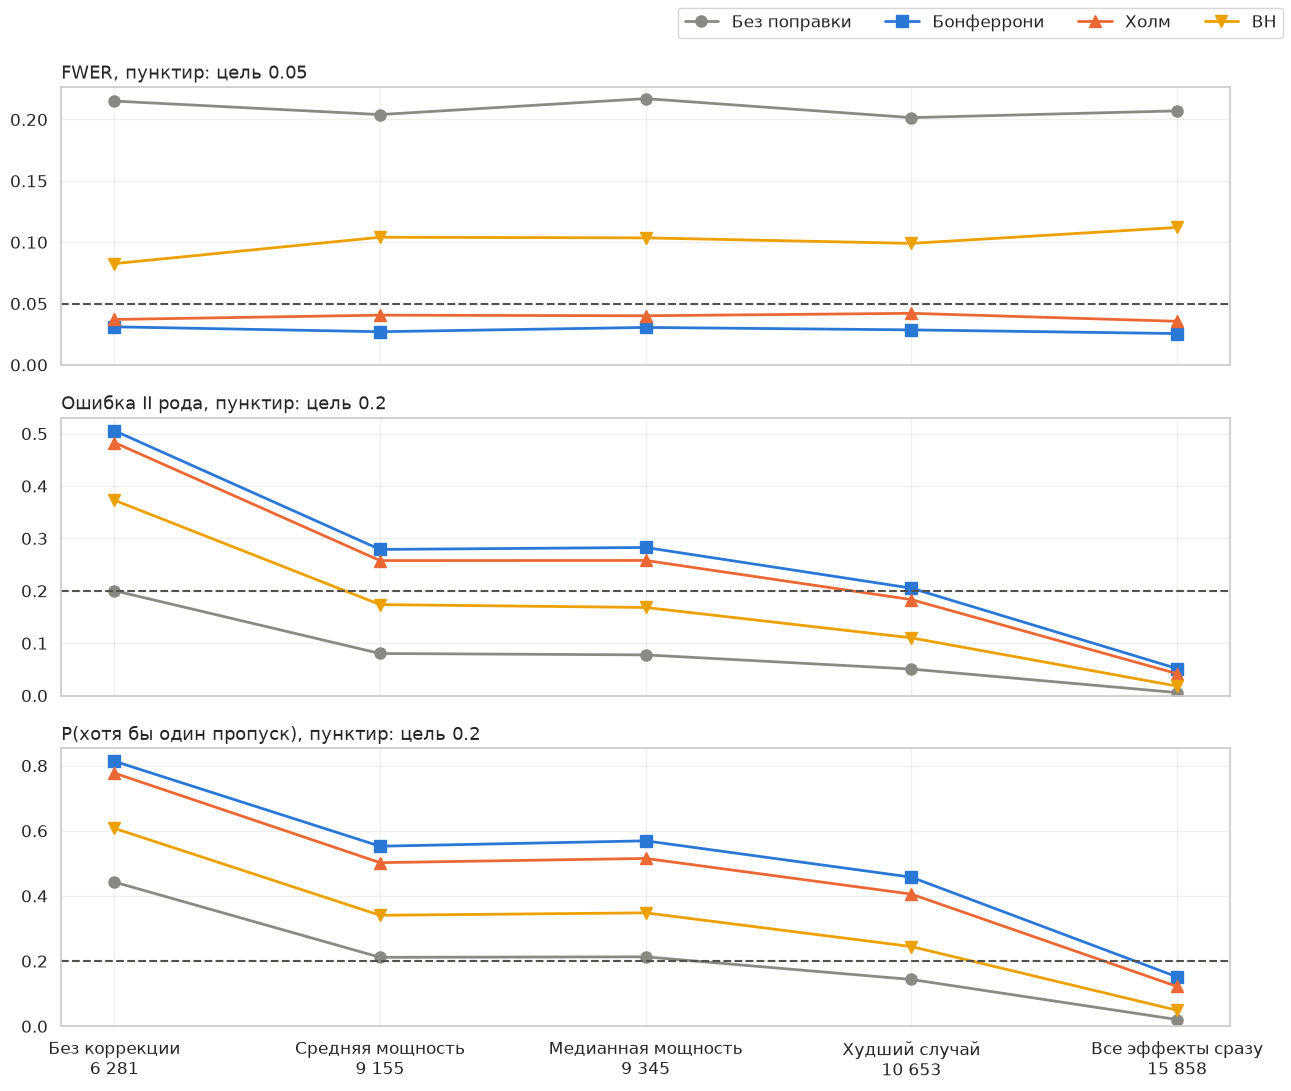

FWER  Ошибка II рода  \
Сценарий           Метод                                 
Без коррекции      Без поправки  0.215           0.200   
                   Бонферрони    0.031           0.506   
                   Холм          0.037           0.483   
                   BH            0.082           0.373   
Средняя мощность   Без поправки  0.204           0.080   
                   Бонферрони    0.027           0.279   
                   Холм          0.040           0.258   
                   BH            0.104           0.174   
Медианная мощность Без поправки  0.217           0.078   
                   Бонферрони    0.030           0.283   
                   Холм          0.040           0.258   
                   BH            0.104           0.168   
Худший случай      Без поправки  0.202           0.050   
                   Бонферрони    0.028           0.205   
                   Холм          0.042           0.183   
                   BH            0.099           0.110   
Все эффекты сразу  Без поправки  0.207           0.006   
                   Бонферрони    0.026           0.051   
                   Холм          0.036           0.042   
                   BH            0.112           0.018   

                                 P(хотя бы один пропуск)  
Сценарий           Метод                                  
Без коррекции      Без поправки                    0.442  
                   Бонферрони                      0.814  
                   Холм                            0.777  
                   BH                              0.608  
Средняя мощность   Без поправки                    0.212  
                   Бонферрони                      0.552  
                   Холм                            0.502  
                   BH                              0.340  
Медианная мощность Без поправки                    0.213  
                   Бонферрони                      0.569  
                   Холм                            0.515  
                   BH                              0.348  
Худший случай      Без поправки                    0.144  
                   Бонферрони                      0.458  
                   Холм                            0.406  
                   BH                              0.244  
Все эффекты сразу  Без поправки                    0.020  
                   Бонферрони                      0.152  
                   Холм                            0.122  
                   BH                              0.049

In [29]:
scenario_errors = {
    name: simulate_design(df["metric"].values, effect, size, n_groups, n_iter=2000, alpha=alpha, rng=rng)
    for name, size in scenarios.items()
}

labels = [f"{name}\n{size:,}".replace(',', ' ') for name, size in scenarios.items()]
targets = {'FWER': alpha, 'Ошибка II рода': beta, 'P(хотя бы один пропуск)': beta}

fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
for ax, (metric, target) in zip(axes, targets.items()):
    for method, (color, marker) in METHOD_STYLE.items():
        if method in base_errors.index:
            values = [scenario_errors[name].loc[method, metric] for name in scenarios]
            ax.plot(labels, values, color=color, marker=marker, markersize=8, linewidth=2, label=method)
    ax.axhline(target, color=REFERENCE_COLOR, linestyle='--', linewidth=1.5)
    ax.set_title(f'{metric}, пунктир: цель {target}', loc='left')
    ax.set_ylim(bottom=0)
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='upper right', ncol=4)
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

pd.concat(scenario_errors, names=['Сценарий', 'Метод']).round(3)

Сравним сценарии с целью $\beta = 0.2$:

* **Худший случай** (+70% к размеру группы) даёт ожидаемую ошибку II рода: около 0.2 у Бонферрони и 0.18 у Холма. Именно этот вариант гарантирует заданную мощность методов контроля FWER.
* **Средняя и медианная мощность** (+46–49%) в нашем сетапе не дотягивают: у Холма ошибка II рода равна примерно 0.26. Причина в том, что реальных эффектов только 4 из 10, а их p-value самые маленькие и проверяются на самых строгих порогах от $\alpha/10$ до $\alpha/7$. Эти подходы рассчитаны на случай, когда реальный эффект есть во всех сравнениях. Зато для BH такого размера выборки хватает.
* **Все эффекты сразу** (+153%) гарантирует, что мы обнаружим все 4 эффекта с вероятностью не меньше 80%. Вероятность хотя бы одного пропуска равна примерно 0.15 у Бонферрони и 0.12 у Холма. Она ниже 0.2, потому что неравенство Буля даёт верхнюю границу.

Практический вывод: если нужна гарантия для методов контроля FWER, рассчитывайте выборку по поправке Бонферрони, а анализ проводите методом Холма.

Иногда для обнаружения всех эффектов сразу советуют делить $\alpha$ на $m^2$. Такое правило не имеет обоснования: оно не учитывает число реальных эффектов $k$ и целевую $\beta$. В нашем случае оно дало бы примерно 14.9 тыс. на группу, что близко к результату формулы лишь по совпадению.

## На какую метрику смотреть?

Почти в любом A/B-тесте метрик много, и это создаёт ещё один слой множественности. Обычно у менеджеров и аналитиков есть несколько ключевых показателей, на которые они смотрят в первую очередь, но такой интуитивный фильтр не даёт гарантий по ошибкам.

Формальный подход предлагает [фреймворк от Spotify](https://arxiv.org/abs/2402.11609). Его главная идея в том, что поправки нужно выводить из **правила принятия решения**, а не применять ко всем метрикам сразу.

| Тип метрики | Что проверяем | Нужно для запуска | Уровень значимости |
| :--- | :--- | :--- | :--- |
| Успеха (success) | Метрика улучшилась (superiority) | **Хотя бы одна** значимо лучше | $\alpha / S$, где $S$ — число метрик успеха |
| Защитная (guardrail) | Метрика не хуже допустимой границы (non-inferiority) | **Все** значимо не хуже | $\alpha$, без поправки |

Логика здесь зеркальная:

* Условие **«хотя бы одна»** даёт много шансов случайно пройти проверку, поэтому растёт ошибка первого рода и нужна поправка на $\alpha$.
* Условие **«все»** требует пройти каждую проверку, поэтому случайно пройти их сложнее. Ошибка первого рода не растёт, зато падает мощность: решение «запускаем» становится всё менее вероятным даже у хорошей фичи.

Поэтому для $G$ защитных метрик поправляют не $\alpha$, а $\beta$: все тесты рассчитываются на мощность $1 - \frac{\beta}{G + 1}$.

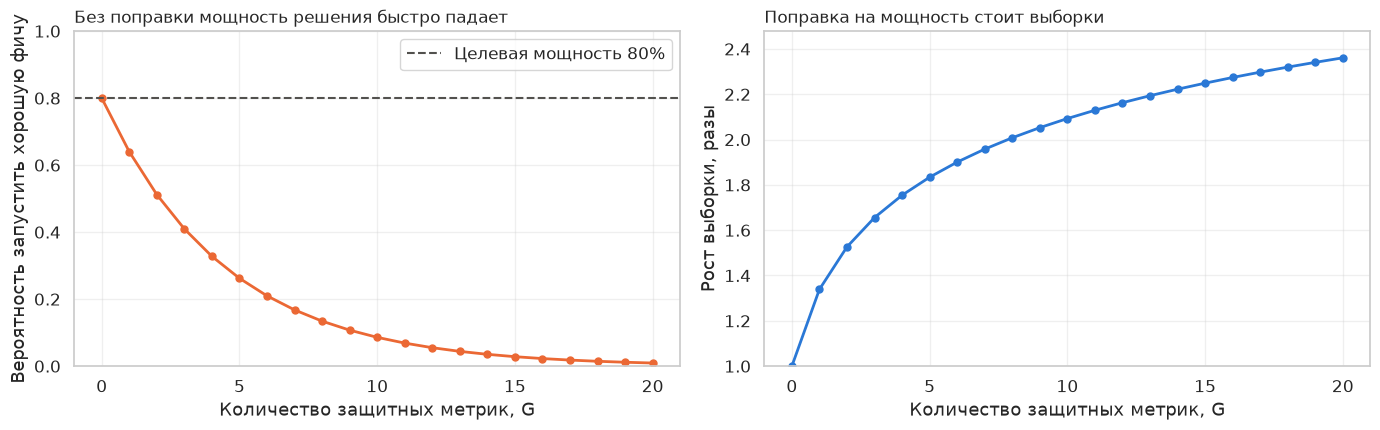

Мощность решения при G = 10 без поправки: 8.6%
Рост выборки при G = 10 с поправкой: в 2.09 раза


In [30]:
guardrails = np.arange(0, 21)
power_unadjusted = 0.8 ** (guardrails + 1)  # независимые метрики, мощность каждого теста 80%
beta_total = 0.2
z_alpha = stats.norm.ppf(1 - 0.05 / 2)
sample_multiplier = ((z_alpha + stats.norm.ppf(1 - beta_total / (guardrails + 1))) / (z_alpha + stats.norm.ppf(1 - beta_total))) ** 2

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(guardrails, power_unadjusted, color=NULL_COLOR, linewidth=2, marker='o', markersize=5)
axes[0].axhline(0.8, color=REFERENCE_COLOR, linestyle='--', linewidth=1.5, label='Целевая мощность 80%')
axes[0].set_ylim(0, 1)
axes[0].set_title('Без поправки мощность решения быстро падает', loc='left', fontsize=12)
axes[0].set_xlabel('Количество защитных метрик, G')
axes[0].set_ylabel('Вероятность запустить хорошую фичу')
axes[0].legend()

axes[1].plot(guardrails, sample_multiplier, color=REAL_COLOR, linewidth=2, marker='o', markersize=5)
axes[1].set_ylim(1, sample_multiplier.max() * 1.05)
axes[1].set_title('Поправка на мощность стоит выборки', loc='left', fontsize=12)
for ax in axes:
    ax.set_xticks(np.arange(0, 21, 5))
axes[1].set_xlabel('Количество защитных метрик, G')
axes[1].set_ylabel('Рост выборки, разы')

plt.tight_layout()
plt.show()

print(f"Мощность решения при G = 10 без поправки: {power_unadjusted[10]:.1%}")
print(f"Рост выборки при G = 10 с поправкой: в {sample_multiplier[10]:.2f} раза")

В полной версии правила Spotify добавляются ещё две проверки:

* **Метрики ухудшения (deterioration):** запуск блокируется, если любая метрика успеха, защитная метрика или дополнительная метрика ухудшения значимо упала.
* **Проверки качества (quality):** запуск блокируется, если эксперимент проведён некорректно. Например, есть sample ratio mismatch или различия групп до начала воздействия.

Для этих проверок авторы выделяют отдельный бюджет ошибки $\alpha_-$, делят его на число тестов и дополнительно уменьшают допустимую $\beta$. Подробности есть в [статье](https://arxiv.org/abs/2402.11609).

**Вопрос.** В отчёте теста одна целевая метрика (заказы за 7 дней), четыре guardrail и пятнадцать диагностических. Аналитик «для честности» применяет процедуру Бенджамини–Хохберга ко всем двадцати p-value. Коллега возражает: поправка нужна только целевой метрике. Кто прав?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Никто полностью: поправку выводят из правила решения, а не из числа метрик в отчёте. Метрика успеха одна, поэтому её проверяют на исходном уровне α: «хотя бы одна из одной» шансов на случайный успех не добавляет. Для guardrail-метрик правило «все должны пройти» не раздувает ошибку первого рода, зато снижает мощность решения, поэтому поправляют β, то есть закладывают больше выборки. Диагностические метрики решения не принимают, их можно читать без поправки, но как гипотезы, а не как находки (если хочется отобрать интересные, тогда уже BH внутри их семейства). Общая BH на все двадцать вредна: порог для целевой метрики начинает зависеть от шума в диагностических, и решение по ней может поменяться из-за кликов по кнопке.

</details>

Правило запуска определяет, какие метрики и с какой поправкой проверять. Но так же важно, **на каких пользователях** их считать и как складывать части теста в общий итог. Прежде чем резать результат на сегменты, разберём два частных случая: анализ только затронутых пользователей (триггер) и сложение периодов с разной долей теста (парадокс Симпсона).

## Триггеринг и разбавление эффекта

Часто изменение касается только части пользователей. Новый баннер «бесплатная доставка от 700 ₽» видят те, у кого в корзине от 500 до 699 ₽, а это 8% пользователей. Если считать эффект по всем, он разбавлен: остальные 92% не изменились, и шум от них только мешает.

Отсюда идея **анализа по триггеру**: сравнивать только тех, кого изменение могло затронуть. Это повышает мощность, но работает при условии: **триггер должен определяться одинаково в обеих группах**, то есть в контроле нужно логировать «пользователь попал бы под баннер». Иначе сравнивают несравнимое.

Сравним три способа анализа на симуляции: по всем пользователям (ITT), по триггеру в обеих группах и неправильный, где в тесте триггером считается «увидел баннер» (а это зависит от поведения после назначения: баннер видят те, кто дошёл до него в интерфейсе, а таких среди активных больше), а в контроле просто «подходил под условия». Истинный эффект баннера на конверсию среди затронутых +4 п.п.

In [31]:
def trigger_trial(rng, n=40000, effect=.04, trigger_rate=.08):
    """Один A/B: в обеих группах n пользователей, затронуты 8% (корзина 500–699 ₽). Вовлечённые среди них конвертируются лучше."""
    arm = np.r_[np.zeros(n), np.ones(n)].astype(bool)
    eligible = rng.random(2 * n) < trigger_rate
    engaged = rng.random(2 * n) < .6
    base = np.where(eligible, np.where(engaged, .46, .31), .12)
    converted = (rng.random(2 * n) < base + effect * (eligible & arm)).astype(float)
    control, test = converted[~arm], converted[arm]
    seen = (eligible & engaged)[arm]
    return {'itt': diff_p(control, test), 'trigger': diff_p(control[eligible[~arm]], test[eligible[arm]]),
            'wrong': diff_p(control[eligible[~arm]], test[seen]), 'share': eligible[arm].mean()}


def trigger_summary(effect, reps=300):
    trials = [trigger_trial(np.random.default_rng(seed), effect=effect) for seed in range(reps)]
    out = {}
    for key in ('itt', 'trigger', 'wrong'):
        deltas = np.array([t[key][0] for t in trials])
        pvalues = np.array([t[key][2] for t in trials])
        out[key] = (deltas.mean(), (pvalues < .05).mean())
    return out


null_case, effect_case = trigger_summary(0.0), trigger_summary(.04)
names = {'itt': 'по всем пользователям', 'trigger': 'по триггеру в обеих группах', 'wrong': 'неправильный триггер'}
table = pd.DataFrame({
    'оценка при нулевом эффекте, п.п.': {names[k]: 100 * v[0] for k, v in null_case.items()},
    'доля значимых при нулевом эффекте': {names[k]: v[1] for k, v in null_case.items()},
    'оценка при эффекте 4 п.п. среди затронутых, п.п.': {names[k]: 100 * v[0] for k, v in effect_case.items()},
    'доля значимых при эффекте': {names[k]: v[1] for k, v in effect_case.items()},
})
print(table.round(3).to_string())

                             оценка при нулевом эффекте, п.п.  доля значимых при нулевом эффекте  оценка при эффекте 4 п.п. среди затронутых, п.п.  доля значимых при эффекте
по всем пользователям                                   0.016                              0.050                                             0.335                      0.277
по триггеру в обеих группах                             0.100                              0.060                                             4.088                      0.903
неправильный триггер                                    6.095                              0.993                                            10.097                      1.000


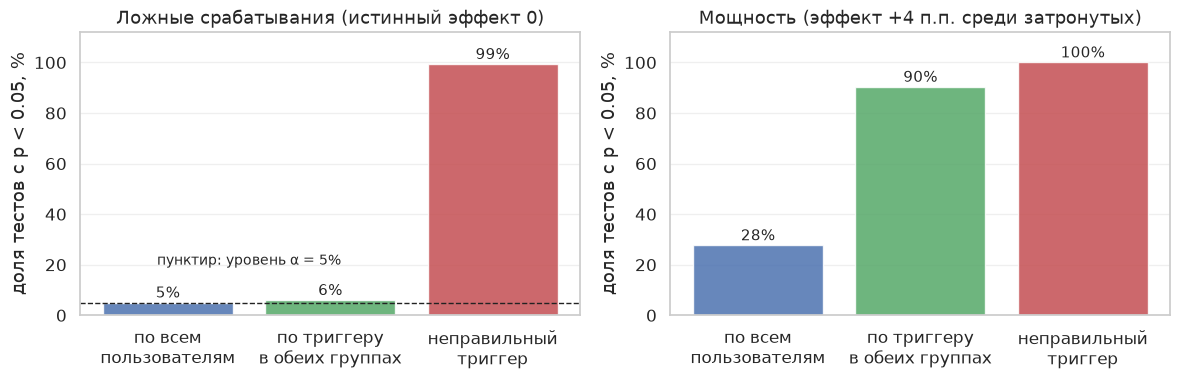

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels = ['по всем\nпользователям', 'по триггеру\nв обеих группах', 'неправильный\nтриггер']
colors = [BLUE, GREEN, RED]
for ax, case, title in ((axes[0], null_case, 'Ложные срабатывания (истинный эффект 0)'), (axes[1], effect_case, 'Мощность (эффект +4 п.п. среди затронутых)')):
    values = [100 * case[k][1] for k in ('itt', 'trigger', 'wrong')]
    ax.bar(labels, values, color=colors, alpha=.85)
    for k, value in enumerate(values):
        ax.text(k, value + 2, f'{value:.0f}%', ha='center', fontsize=11)
    ax.set_ylim(0, 112)
    ax.set_ylabel('доля тестов с p < 0.05, %')
    ax.set_title(title)
    ax.grid(axis='x', visible=False)
axes[0].axhline(5, color='#222222', linestyle='--', linewidth=1)
axes[0].text(.5, 20, 'пунктир: уровень α = 5%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

Три вывода.

* **Анализ по всем пользователям честен, но слаб:** уровень значимости держит (5%), но при эффекте, разбавленном в 12 раз, находит его лишь в 28% тестов.
* **Анализ по триггеру с одинаковым определением в группах** тоже держит уровень значимости (6%) и находит эффект в 90% тестов.
* **Неправильный триггер ломает всё:** он «находит» эффект в 99% тестов, даже когда его нет (среднюю оценку +6 п.п. при нулевом эффекте). Условие «увидел баннер» зависит от поведения после назначения, поэтому в тесте остаются самые вовлечённые, и разницу создаёт отбор, а не баннер.

Чтобы пересчитать эффект на триггерной подвыборке в эффект на всех пользователей, нужна **формула разбавления** (Deng, Hu, [WSDM 2015](https://exp-platform.com/dilution/)). Для аддитивной user-level метрики, например конверсии, и в предположении, что на незатронутых пользователей эффекта нет, она проста: Δ_overall = Δ_trigger × N_trigger / N. Для ratio-метрик нужны дополнительные множители, и авторы предупреждают, что на практике часто применяют приближённые или неверные формулы. Они предлагают объединить оценку по триггеру и пересчёт в один анализ, что даёт несмещённую оценку общего эффекта с большей мощностью.

In [33]:
trial = trigger_trial(np.random.default_rng(21))
delta_tr, se_tr, _ = trial['trigger']
delta_itt, se_itt, _ = trial['itt']
share = trial['share']
print(f'Доля затронутых: {100 * share:.1f}%')
print(f'Эффект по триггеру: {100 * delta_tr:+.2f} п.п. (95% ДИ {100 * (delta_tr - 1.96 * se_tr):+.2f}; {100 * (delta_tr + 1.96 * se_tr):+.2f})')
print(f'Разбавленный на всех (Δ × доля): {100 * delta_tr * share:+.2f} п.п. (95% ДИ {100 * (delta_tr - 1.96 * se_tr) * share:+.2f}; {100 * (delta_tr + 1.96 * se_tr) * share:+.2f})')
print(f'Прямая оценка по всем:           {100 * delta_itt:+.2f} п.п. (95% ДИ {100 * (delta_itt - 1.96 * se_itt):+.2f}; {100 * (delta_itt + 1.96 * se_itt):+.2f})')

Доля затронутых: 7.9%
Эффект по триггеру: +2.92 п.п. (95% ДИ +0.48; +5.35)
Разбавленный на всех (Δ × доля): +0.23 п.п. (95% ДИ +0.04; +0.42)
Прямая оценка по всем:           +0.08 п.п. (95% ДИ -0.41; +0.57)


Истинный эффект на всех пользователей равен 0.04 × 0.08 = 0.32 п.п. Обе оценки с ним согласуются, но интервал разбавленной оценки примерно в 2.6 раза уже прямого: именно в этом выигрыш триггера. Использовать его честно можно, только если мы заранее логируем условие триггера для обеих групп и определяем его по данным **до назначения** (или по признакам, на которые воздействие повлиять не может).

**Вопрос.** В тесте 50/50 SRM нет. Метрика «среднее число заказов на активного пользователя» упала на 5%, а число заказов на пользователя не изменилось. Что проверить в первую очередь?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Сначала проверяем, не изменился ли сам набор «активных» пользователей: это метрический SRM, а не ухудшение. «Активный пользователь» определяется поведением после назначения: это тот, кто сделал хотя бы одно действие. Если изменение повлияло на то, сколько пользователей стали активными (например, новые слабоактивные пользователи начали заходить), знаменатель меняется, и метрика сравнивает разные наборы людей. Проверяем число активных пользователей в группах (метрический SRM), смотрим числитель и знаменатель отдельно и опираемся на метрику, посчитанную на всех пользователях, которым назначено воздействие.

</details>

## Парадокс Симпсона: меняющиеся доли

Тест часто запускают постепенно: сначала на малой доле трафика, потом шире, чтобы ограничить ущерб от возможного бага. Но если доля теста меняется во времени, а поведение пользователей тоже меняется во времени (будни и выходные, акции, сезон), общий итог по периоду может показать **обратный** знак по сравнению с каждым днём. Это парадокс Симпсона. Crook, Frasca, Kohavi и Longbotham ([KDD 2009](https://exp-platform.com/seven-pitfalls/)) называют его среди ловушек, которые они встречали при запуске экспериментов в вебе: при постепенном росте доли теста легко выбрать неправильного победителя.

Наш случай. Неделя теста: в будни тест получает 50% трафика, а в выходные его, из осторожности перед пиком, снижают до 10%. В выходные конверсия выше. Тест на самом деле **повышает** конверсию на 1 п.п. в любой день.

In [34]:
def simulate_ramp(rng, daily=30000, effect=.01):
    """Неделя теста: конверсия и доля теста зависят от дня; истинный эффект теста +1 п.п. каждый день."""
    days = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
    base = [.08] * 5 + [.14] * 2
    share = [.5] * 5 + [.1] * 2
    rows = []
    for day, b, s in zip(days, base, share):
        n_test = rng.binomial(daily, s)
        n_ctrl = daily - n_test
        rows.append({'день': day, 'доля теста': s, 'n_контроль': n_ctrl, 'n_тест': n_test,
                     'конверсия_контроль': rng.binomial(n_ctrl, b) / n_ctrl, 'конверсия_тест': rng.binomial(n_test, b + effect) / n_test})
    return pd.DataFrame(rows)


ramp = simulate_ramp(np.random.default_rng(0))
conv_ctrl = (ramp['конверсия_контроль'] * ramp['n_контроль']).sum() / ramp['n_контроль'].sum()
conv_test = (ramp['конверсия_тест'] * ramp['n_тест']).sum() / ramp['n_тест'].sum()
daily_delta = ramp['конверсия_тест'] - ramp['конверсия_контроль']
daily_var = ramp['конверсия_контроль'] * (1 - ramp['конверсия_контроль']) / ramp['n_контроль'] + ramp['конверсия_тест'] * (1 - ramp['конверсия_тест']) / ramp['n_тест']
weights = 1 / daily_var
stratified = (weights * daily_delta).sum() / weights.sum()
stratified_se = np.sqrt(1 / weights.sum())
pooled_delta = conv_test - conv_ctrl
pooled_se = np.sqrt(conv_ctrl * (1 - conv_ctrl) / ramp['n_контроль'].sum() + conv_test * (1 - conv_test) / ramp['n_тест'].sum())
print(ramp.assign(**{'разница, п.п.': (100 * daily_delta).round(2)}).round(4).to_string(index=False))
print(f'\nОбщий итог за неделю: контроль {100 * conv_ctrl:.2f}%, тест {100 * conv_test:.2f}%, разница {100 * pooled_delta:+.2f} п.п. (SE {100 * pooled_se:.2f})')
print(f'С учётом дня (дни взвешены по точности): {100 * stratified:+.2f} п.п. (SE {100 * stratified_se:.2f}), истина +1.00')

день  доля теста  n_контроль  n_тест  конверсия_контроль  конверсия_тест  разница, п.п.
  Пн         0.5       14892   15108              0.0802          0.0904           1.02
  Вт         0.5       15040   14960              0.0791          0.0907           1.17
  Ср         0.5       14851   15149              0.0810          0.0899           0.89
  Чт         0.5       15016   14984              0.0812          0.0922           1.09
  Пт         0.5       14951   15049              0.0825          0.0874           0.48
  Сб         0.1       26957    3043              0.1389          0.1623           2.34
  Вс         0.1       26951    3049              0.1421          0.1456           0.35

Общий итог за неделю: контроль 10.58%, тест 9.49%, разница -1.09 п.п. (SE 0.13)
С учётом дня (дни взвешены по точности): +0.96 п.п. (SE 0.14), истина +1.00


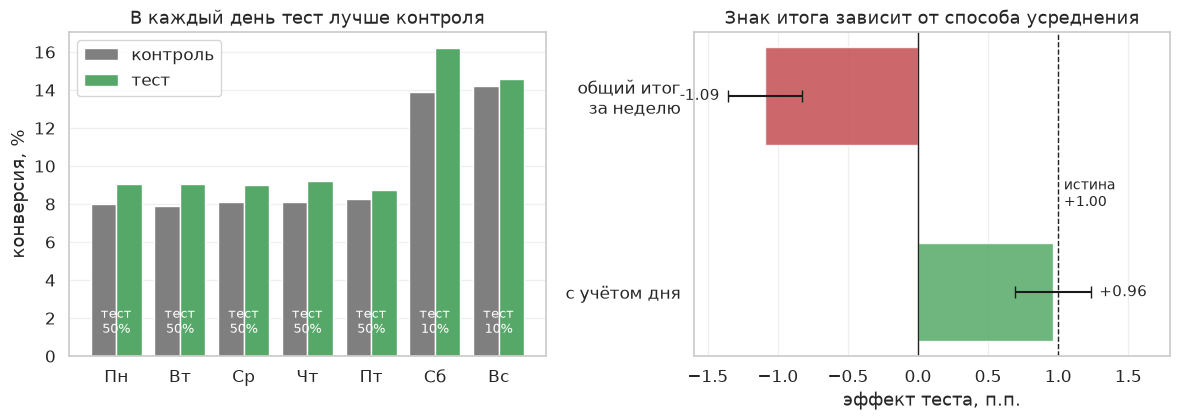

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
x = np.arange(7)
axes[0].bar(x - .2, 100 * ramp['конверсия_контроль'], width=.4, color=GRAY, label='контроль')
axes[0].bar(x + .2, 100 * ramp['конверсия_тест'], width=.4, color=GREEN, label='тест')
for k, s in enumerate(ramp['доля теста']):
    axes[0].text(k, 1, f'тест\n{100 * s:.0f}%', ha='center', va='bottom', fontsize=9, color='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels(ramp['день'])
axes[0].set_ylabel('конверсия, %')
axes[0].set_title('В каждый день тест лучше контроля')
axes[0].legend(loc='upper left')
axes[0].grid(axis='x', visible=False)
estimates = [('общий итог\nза неделю', pooled_delta, pooled_se, RED), ('с учётом дня', stratified, stratified_se, GREEN)]
for k, (name, value, se, color) in enumerate(estimates):
    axes[1].barh(k, 100 * value, xerr=196 * se, color=color, alpha=.85, height=.5, capsize=4)
    axes[1].text(100 * value + np.sign(value) * (196 * se + .06), k, f'{100 * value:+.2f}', va='center', ha='left' if value > 0 else 'right', fontsize=11)
axes[1].axvline(1.0, color='#222222', linestyle='--', linewidth=1)
axes[1].text(1.04, .5, 'истина\n+1.00', fontsize=10, va='center')
axes[1].set_xlim(-1.6, 1.8)
axes[1].axvline(0, color='#222222', linewidth=1)
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels([e[0] for e in estimates])
axes[1].invert_yaxis()
axes[1].set_xlabel('эффект теста, п.п.')
axes[1].set_title('Знак итога зависит от способа усреднения')
axes[1].grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

Тест стал выглядеть вредным (общий итог −1.09 п.п. при стандартной ошибке 0.13): в нём слишком много будней, когда конверсия низкая, и слишком мало выходных, когда она высокая. С учётом дня оценка +0.96 п.п. при истинных +1.00. Разница между группами в итоге складывается из эффекта теста **и разной структуры дней**. В каждый отдельный день тест лучше контроля.

Как с этим жить:

* **Не менять долю теста по ходу, если можно.** Лучше подбирать фиксированную долю и держать её весь тест.
* **Если долю всё же меняют, анализировать с учётом периода:** считать эффект внутри каждого периода с постоянной долей и объединять (например, взвешивая по точности, как выше, или регрессией с фиксированными эффектами дня). Тогда структура дней уходит из сравнения.
* **Проверять SRM по периодам.** Если доля менялась, суммарная доля групп за весь тест не равна плановой, и обычная проверка SRM по тесту целиком даст ложную тревогу. Её нужно делать внутри каждого периода с постоянной долей.

## Сегменты: скрытая множественность и сегмент, зависящий от воздействия

Результат хочется разрезать: по платформе, городу, давности пользователя. Разрезы полезны для отладки и поиска неоднородности эффекта, но у них три ловушки.

**Первая: множественность.** Если смотреть 20 сегментов, значимый хотя бы в одном найдётся с вероятностью около 64% даже при нулевом эффекте. Покажем на A/A-тесте с 20 сегментами по 4000 пользователей в группе.

**Вопрос.** После теста аналитик сообщает: «на Android эффект значим (p = 0.03), на iOS нет (p = 0.30), запускаем только на Android». Что вы проверите до решения?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Скорее всего, разумнее запускать на всех, но сначала три проверки. Первое: значимо ли различие эффектов между платформами. Значим в одном и не значим в другом — не доказательство различия: сегменты могут отличаться только размером и, соответственно, мощностью. Второе: был ли сегмент одним из заранее выбранных или аналитик нашёл его среди многих разрезов (множественность). Третье: одинакова ли доля платформ в группах. Если различия эффектов нет, а платформа запланирована заранее, разумнее запускать на всех и смотреть на объединённый эффект.

</details>

In [36]:
def aa_segments(rng, reps=1000, segments=20, n=4000, p=.10):
    """A/A: доля тестов, где хотя бы один сегмент значим без поправки и после поправки Холма."""
    any_raw, any_holm = 0, 0
    for _ in range(reps):
        a, b = rng.binomial(n, p, segments), rng.binomial(n, p, segments)
        pooled = (a + b) / (2 * n)
        z = (b - a) / n / np.sqrt(2 * pooled * (1 - pooled) / n)
        pvalues = 2 * st.norm.sf(np.abs(z))
        any_raw += (pvalues < .05).any()
        ordered = np.sort(pvalues)
        any_holm += ordered[0] <= .05 / segments  # Холм отвергает хоть одну гипотезу, только если min p ≤ α/m
    return any_raw / reps, any_holm / reps


aa_raw, aa_holm = aa_segments(np.random.default_rng(1))
print(f'Хотя бы один значимый из 20 сегментов в A/A: без поправки {100 * aa_raw:.0f}%, с поправкой Холма {100 * aa_holm:.1f}%')

Хотя бы один значимый из 20 сегментов в A/A: без поправки 65%, с поправкой Холма 5.4%


Без поправки «находка» есть в двух тестах из трёх, с поправкой ложных срабатываний около 5%. Сегменты, которые мы будем смотреть, нужно **заранее перечислить** и считать единым семейством гипотез (см. раздел о множественном тестировании выше).

**Вторая ловушка: «значимо здесь, не значимо там» ничего не говорит о разнице эффектов.** Допустим, у iOS 40 тысяч пользователей в группе, у Android 10 тысяч, а истинный эффект везде одинаков: +0.8 п.п. к конверсии 10%. Мощности у сегментов разные, поэтому часто значим только iOS. Но вывод «на Android не работает» неверен. Правильно проверять **взаимодействие**: значимо ли отличаются эффекты в сегментах.

In [37]:
def significant_here_not_there(rng, reps=3000, p=.10, effect=.008, sizes=(40000, 10000)):
    """Эффект одинаков в двух сегментах. Как часто значим только в первом и как часто значимо взаимодействие."""
    only_first, interaction, only_first_and_interaction = 0, 0, 0
    for _ in range(reps):
        deltas, ses = [], []
        for n in sizes:
            a, b = rng.binomial(n, p), rng.binomial(n, p + effect)
            deltas.append((b - a) / n)
            ses.append(np.sqrt(2 * p * (1 - p) / n))
        significant = [abs(d / s) > 1.96 for d, s in zip(deltas, ses)]
        inter = abs((deltas[0] - deltas[1]) / np.hypot(*ses)) > 1.96
        interaction += inter
        if significant[0] and not significant[1]:
            only_first += 1
            only_first_and_interaction += inter
    return only_first / reps, interaction / reps, only_first_and_interaction / max(only_first, 1)


only_first, inter_all, inter_in_only_first = significant_here_not_there(np.random.default_rng(2))
print(f'Значим только iOS (не значим Android): {100 * only_first:.0f}% тестов')
print(f'Взаимодействие значимо: {100 * inter_all:.1f}% тестов при истинном отсутствии взаимодействия')
print(f'Среди тестов «только iOS» взаимодействие значимо в {100 * inter_in_only_first:.1f}%')

Значим только iOS (не значим Android): 48% тестов
Взаимодействие значимо: 5.1% тестов при истинном отсутствии взаимодействия
Среди тестов «только iOS» взаимодействие значимо в 4.7%


Половина тестов даёт картину «работает на iOS, на Android не работает», хотя эффекты равны. Проверка на взаимодействие почти никогда не подтверждает разницу, и это правильно: данных для такого вывода просто нет. В задаче «катим только на Android» нужно смотреть на разницу эффектов и её доверительный интервал.

**Третья ловушка: сегмент определён по признаку, на который влияет воздействие.** В примере из статьи Microsoft: в Bing разрезали пользователей на тех, кто увидел «глубокие ссылки» в выдаче, и тех, кто не увидел. В обоих сегментах число сессий на пользователя значимо выросло, а в целом по тесту осталось прежним. Эксперимент на сессии не влиял, но он изменил, кто попадает в сегмент: менее активные пользователи выпали из первого сегмента во второй, и в обоих средняя активность выросла.

Воспроизведём механизм. В нашем кейсе сегмент «видит блок рекомендаций» зависит от активности, а тест сместил порог: умеренно активные пользователи перестали его видеть. Сессии никак не менялись.

In [38]:
def post_treatment_segments(rng, n=60000):
    """Сессии не меняются, но тест меняет состав сегмента «видит блок»: умеренно активные пользователи в тесте его не видят."""
    activity = rng.gamma(2.0, 1.0, 2 * n)
    arm = np.r_[np.zeros(n), np.ones(n)].astype(bool)
    sees = np.where(arm, activity > 3.0, activity > 2.2)
    sessions = rng.poisson(activity).astype(float)
    rows = []
    for name, mask in (('видят блок', sees), ('не видят блок', ~sees), ('все пользователи', np.ones(2 * n, bool))):
        a, b = sessions[~arm & mask], sessions[arm & mask]
        effect, se = rel_effect(a, b)
        rows.append({'сегмент': name, 'эффект на сессии': effect, 'SE': se, 'доля в контроле': mask[~arm].mean(), 'доля в тесте': mask[arm].mean()})
    share_p = st.chi2_contingency([[sees[~arm].sum(), (~sees[~arm]).sum()], [sees[arm].sum(), (~sees[arm]).sum()]])[1]
    return pd.DataFrame(rows).set_index('сегмент'), share_p


segments, share_p = post_treatment_segments(np.random.default_rng(3))
print(segments.assign(**{'эффект на сессии': segments['эффект на сессии'].map(pct), 'SE': (100 * segments['SE']).round(1),
                         'доля в контроле': (100 * segments['доля в контроле']).round(1), 'доля в тесте': (100 * segments['доля в тесте']).round(1)}).to_string())
print(f'\nПроверка равенства долей сегмента «видят блок» в группах: p {"< 1e-300" if share_p < 1e-300 else "= " + format(share_p, ".1e")}')

                 эффект на сессии   SE  доля в контроле  доля в тесте
сегмент                                                              
видят блок                 +20.6%  0.8             35.6          20.0
не видят блок              +21.7%  0.8             64.4          80.0
все пользователи            -0.9%  0.6            100.0         100.0

Проверка равенства долей сегмента «видят блок» в группах: p < 1e-300


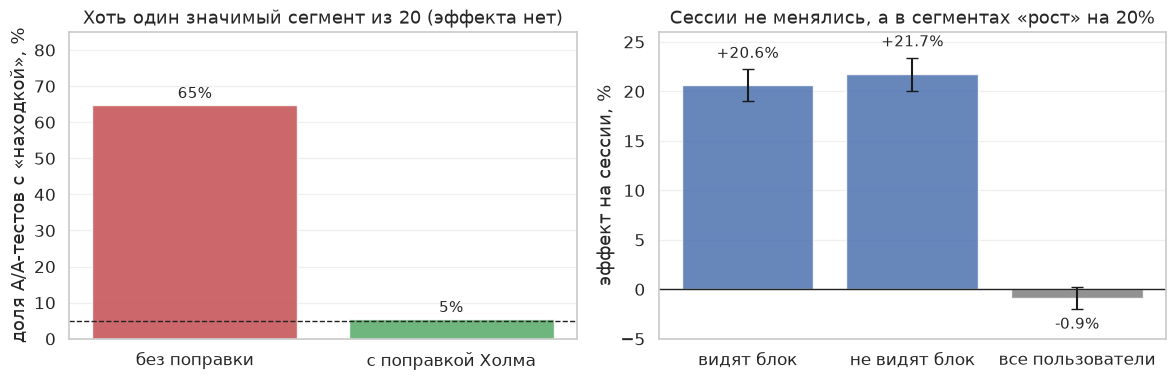

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(['без поправки', 'с поправкой Холма'], [100 * aa_raw, 100 * aa_holm], color=[RED, GREEN], alpha=.85)
for k, v in enumerate([100 * aa_raw, 100 * aa_holm]):
    axes[0].text(k, v + 2, f'{v:.0f}%', ha='center', fontsize=11)
axes[0].axhline(5, color='#222222', linestyle='--', linewidth=1)
axes[0].set_ylim(0, 85)
axes[0].set_ylabel('доля A/A-тестов с «находкой», %')
axes[0].set_title('Хоть один значимый сегмент из 20 (эффекта нет)')
axes[0].grid(axis='x', visible=False)
order = segments.index
values = 100 * segments['эффект на сессии']
axes[1].bar(order, values, yerr=196 * segments['SE'], color=[BLUE, BLUE, GRAY], alpha=.85, capsize=4)
for k, (v, se) in enumerate(zip(values, 196 * segments['SE'])):
    axes[1].text(k, v + se + .8 if v >= 0 else v - se - .8, f'{v:+.1f}%', ha='center', va='bottom' if v >= 0 else 'top', fontsize=11)
axes[1].set_ylim(-5, 26)
axes[1].axhline(0, color='#222222', linewidth=1)
axes[1].set_ylabel('эффект на сессии, %')
axes[1].set_title('Сессии не менялись, а в сегментах «рост» на 20%')
axes[1].grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

Оба сегмента показывают рост около 20%, а общий эффект равен нулю: изменился состав сегментов. Лекарство то же, что для SRM, только на уровне сегмента: **проверять, что доля пользователей в сегменте одинакова в группах** (здесь p ≈ 0, доля упала с 36% до 20%). Если не одинакова, сегмент определён по признаку, на который воздействие повлияло, и его нельзя использовать для сравнения. Безопасны сегменты по признакам, зафиксированным до назначения (платформа, страна, давность регистрации).

## Решение, когда метрики противоречат

Соберём всё в одно правило. Порядок чтения из начала встречи и правило запуска Spotify дают конечный набор исходов, и для каждого решение можно договорить заранее, до того как увидены данные. Разберём, как свести метрики отчёта в одно решение.

**Вопрос.** Отчёт: SRM нет. Заказы за 7 дней (единственная метрика успеха) +1.8%, p = 0.004. Guardrail «время доставки»: +0.6 мин, 95% интервал от −0.1 до +1.3 мин, допустимая граница ухудшения +1 мин. Отписки от пушей без изменений. Из 15 диагностических метрик значимы три. Продакт говорит: «внедряем, время доставки значимо не ухудшилось». Что вы ответите?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Это не «внедряем», а «внедряем с условием» или «продлеваем тест»: guardrail не доказал, что ухудшение меньше допустимого. Guardrail проверяется как non-inferiority: нужно, чтобы весь интервал лежал левее границы +1 мин, а верхний конец +1.3 мин её пересекает. «Значимо не ухудшилось» — это ответ на другой вопрос, при маломощном guardrail он почти всегда будет таким. Варианты: продлить тест до мощности, заложенной для guardrail, или внедрить с порогом отката, долгосрочным holdout и сроком перепроверки, если цена возможных лишних 0.3 мин понятна и меньше выигрыша по заказам (это экономика решения из встречи 1). Три значимые диагностические метрики из пятнадцати решения не меняют: около одной такой «находки» ждём просто по случайности.

</details>

Исходы и решения, которые стоит договорить до запуска:

* **Проверки качества не пройдены** (SRM по пользователям, метрический SRM на знаменателях ключевых метрик, расхождение клиента и сервера) — результат не читаем. Ищем причину, чиним, перезапускаем.
* **Хотя бы одна метрика успеха значимо лучше** (с поправкой на число метрик успеха), **все guardrail прошли non-inferiority**, ничего значимо не ухудшилось — **внедряем**.
* **Метрика успеха значима, guardrail не определился**: интервал пересекает границу, но значимого ухудшения нет — **внедряем с условием** или продлеваем тест. Условие записываем явно: порог отката, holdout, срок перепроверки.
* **Метрика успеха значима, но какая-то метрика значимо ухудшилась** — в текущем виде **не внедряем**. Компромисс возможен, только если цена ухудшения была заранее переведена в деньги и она меньше выигрыша, и это решение принимается явно, а не задним числом.
* **Метрика успеха не значима**, зато «выстрелили» диагностические метрики или незапланированный сегмент — **не внедряем как победу**. Находка становится гипотезой для следующего теста с этой метрикой или сегментом в роли заранее заявленных.
* **Слишком хороший результат** (эффект в разы больше ожидаемого, метрики двигаются непохоже на обычное поведение) — сначала ищем ошибку в данных. Подробнее в разделе «Закон Твайман» в «Дополнительно».

## Чек-лист доверия к тесту

Все ловушки встречи складываются в последовательность проверок. В последнем столбце указано, где тема разобрана.

| Когда | Что проверить | Где разобрано |
|---|---|---|
| До запуска | У теста одна OEC, а не набор «что-нибудь да выстрелит». OEC проверена на корпусе прошлых тестов (чувствительность и согласие с целью). | «Дополнительно» |
| До запуска | Заданы guardrail-метрики и контрметрика для метрики-цели. Они определены до того, как видны данные. | эта встреча |
| До запуска | Если анализ по триггеру, условие триггера логируется в обеих группах и определяется до назначения. | эта встреча |
| До запуска | Длительность не короче полного недельного цикла и затухания новизны; план по доле теста фиксирован. | эта встреча, «Дополнительно» |
| До запуска | Мощность и MDE посчитаны, проверка критерия на A/A сделана. | базовый курс |
| Во время | SRM на уровне пользователей проверяется регулярно, при изменении доли теста внутри каждого периода. | эта встреча |
| Во время | Промежуточные результаты не используются для остановки без специальных методов. | встреча 4 |
| После | Сначала качество данных: SRM, число событий на пользователя в группах, сверка с серверным логом. | эта встреча, «Дополнительно» |
| После | Потом OEC, потом guardrail-метрики, потом диагностические. Ratio-метрики читать вместе с числителем и знаменателем. | эта встреча |
| После | Сегменты заранее перечислены, поправка на множественность применена, эффекты в сегментах сравниваются через взаимодействие, доля сегмента проверена на равенство в группах. | эта встреча |
| После | Если доля теста менялась, эффект считается внутри периодов с постоянной долей. | эта встреча |
| После | Выбросы не искажают оценку, дисперсия снижена методами ускорения (например, CUPED). | базовый курс |
| После | Результат «слишком хорош» или «странный»: эффект в разы больше MDE, метрики двигаются непохоже, эффект быстро затухает — ищем ошибку, а не запускаем. | «Дополнительно» |
| После запуска | Долгосрочный holdout сравнивает реальный эффект с тестовым. Результат пополняет корпус для проверки метрик. | «Дополнительно» |

## Итоги

**Множественность**

* Проверяя много гипотез, мы почти гарантированно получим ложные открытия, если не внесём поправки. Важно заранее определить семейство гипотез.
* FWER ограничивает вероятность хотя бы одной ошибки, а FDR ограничивает их среднюю долю. Выбор зависит от цены ошибки.
* По умолчанию для FWER используйте метод Холма, а для FDR используйте процедуру Бенджамини–Хохберга.
* Поправки снижают мощность, поэтому их нужно закладывать в размер выборки ещё на этапе дизайна.
* При неравных группах правило квадратного корня снижает MDE в сравнениях с контролем.
* Для решений по нескольким метрикам поправка следует из правила запуска: «хотя бы одна» требует поправки $\alpha$, а «все» требует поправки $\beta$.

**Метрики и доверие к тесту**

1. Метрики в тесте играют разные роли: качество данных, OEC, guardrail, диагностика. Читать результат нужно в таком порядке, а решение принимать по OEC.
2. Метрику, которую оптимизируют, накручивают. Защита от этого: guardrail-метрики и контрметрики, определённые до запуска.
3. Метрику проверяют на корпусе прошлых тестов: чувствительность и согласие с целью. Прокси и суррогаты проверяют на уровне экспериментов, а не пользователей.
4. Эффект меняется со временем. Горизонт теста и долгосрочный holdout защищают от новизны и переноса спроса.
5. Ratio-метрики и метрики на подмножествах нельзя читать без числителя и знаменателя: набор наблюдений в группах может отличаться (метрический SRM) или телеметрия может теряться по-разному.
6. Триггер повышает мощность, только если определён одинаково в обеих группах и до назначения.
7. Парадокс Симпсона бывает при меняющейся доле теста и при сегментах, зависящих от воздействия. Сегменты множественны, а различие значимости не есть различие эффектов.
8. Необычно хороший результат чаще всего означает ошибку. Чем лучше результат, тем тщательнее его проверять.

## Правило для команды

1. **Сначала сплит.** До чтения метрик проверяем SRM по пользователям (при менявшейся доле — внутри каждого периода) и знаменатели ключевых метрик. Есть SRM — результат не читаем, ищем причину.
2. **Роли и поправки — в дизайн-доке до запуска.** Метрики успеха (поправка α/S, анализ методом Холма), guardrail с границами non-inferiority и контрметрика к цели (поправка β, то есть больше выборки), список диагностических. Поправку выводим из правила запуска, а не из числа метрик в отчёте.
3. **Диагностические метрики и незапланированные сегменты решений не принимают.** Их находки — гипотезы для следующего теста.
4. **Сегменты — только заранее перечисленные и по признакам до назначения.** Доля сегмента в группах проверена, различие эффектов проверяем через взаимодействие, а не через «значим здесь, не значим там».
5. **Решение — одно из трёх, с записанной причиной.** Внедряем: успех значим, все guardrail прошли. Внедряем с условием: guardrail не определился — с порогом отката, holdout и сроком перепроверки. Не внедряем: ухудшение значимо или успех не значим. Слишком хороший результат сначала проверяем на ошибку.

Дальше: встреча 6 — от теста к портфелю, мета-анализ.

## Дополнительно

Разделы ниже углубляют темы встречи: как распределить трафик между несколькими тестовыми группами, как проверить, что метрика годится в OEC, и ещё несколько ловушек интерпретации.

### Распределение трафика по группам

Снизить число пользователей можно и более хитрым распределением по группам.

Пусть есть одна контрольная группа размера $n_c$, $k$ тестовых групп размера $n_t$ и всего $N$ пользователей, то есть $n_c + k n_t = N$. Каждая тестовая группа сравнивается с контрольной t-тестом:

$$
\Large t = \frac{\bar{X}_t - \bar{X}_c}{\sqrt{\frac{s_t^2}{n_t} + \frac{s_c^2}{n_c}}}
$$

При равных дисперсиях дисперсия разности средних пропорциональна $\frac{1}{n_c} + \frac{1}{n_t}$. Она одинакова во всех $k$ сравнениях, поэтому нам нужно минимизировать:

$$\min_{n_c,\, n_t} \left( \frac{1}{n_c} + \frac{1}{n_t} \right) \quad \text{при условии} \quad n_c + k n_t = N$$

Оптимальные размеры групп равны:

$$n_t = \frac{N}{k + \sqrt{k}}, \quad n_c = \frac{N}{1 + \sqrt{k}}$$

Это **правило квадратного корня**: контрольная группа должна быть в $\sqrt{k}$ раз больше каждой тестовой.

**Вывод**

1. Выразим $n_c = N - k n_t$ и получим функцию одной переменной:
$$
f(n_t) = \frac{1}{N - k n_t} + \frac{1}{n_t}
$$

2. Возьмём производную и приравняем её к нулю:
$$
f'(n_t) = \frac{k}{(N - k n_t)^2} - \frac{1}{n_t^2} = 0
$$

$$
\frac{(N - k n_t)^2}{n_t^2} = k
$$

3. Группы имеют положительный размер, поэтому берём положительный корень:
$$
\frac{N - k n_t}{n_t} = \sqrt{k}
$$

$$
N = n_t (k + \sqrt{k})
$$

$$
n_t = \frac{N}{k + \sqrt{k}}
$$

4. Теперь находим размер контрольной группы:
$$
n_c = N - k n_t = N \left( 1 - \frac{k}{k + \sqrt{k}} \right) = N \frac{\sqrt{k}}{k + \sqrt{k}} = \frac{N}{1 + \sqrt{k}}
$$

Итак, окончательное решение:
$$
\boxed{
\begin{aligned}
n_t &= \frac{N}{k + \sqrt{k}}, \\
n_c &= \frac{N}{1 + \sqrt{k}}.
\end{aligned}
}
$$

При $k = 1$ получаем равное деление пополам, как и должно быть. Ниже посчитаем MDE для $k$ сравнений с контролем, применив поправку Бонферрони $\alpha / k$.

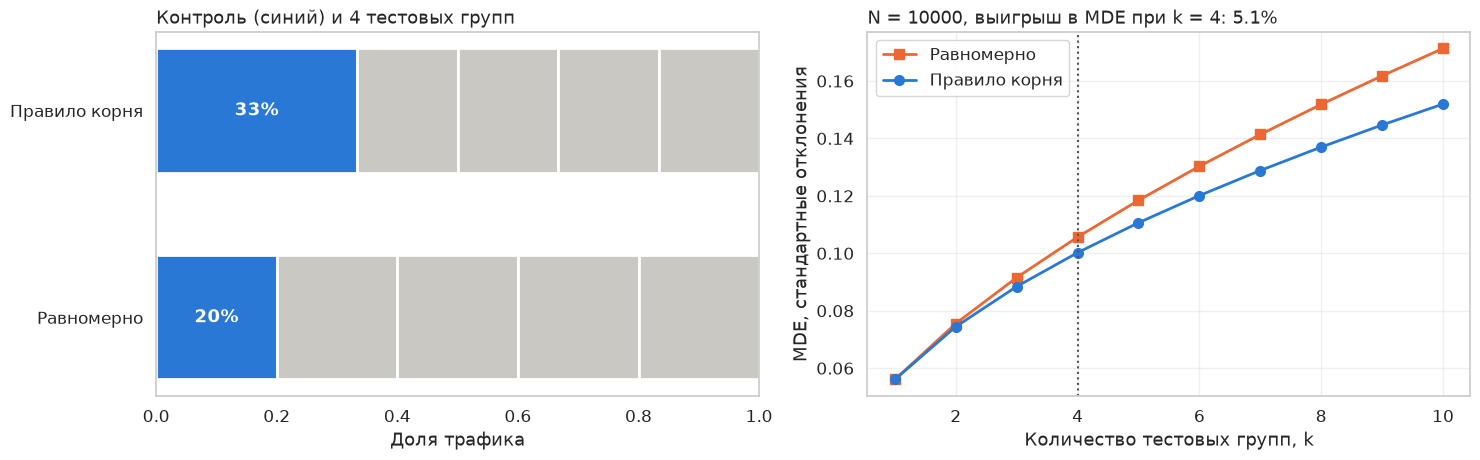

,MDE оптимальное,MDE равномерное,"Улучшение, %"
k,,,
1,0.0560,0.0560,0.0000
2,0.0744,0.0755,1.4412
3,0.0884,0.0915,3.4109
4,0.1002,0.1056,5.1386
5,0.1106,0.1184,6.5938
6,0.1201,0.1303,7.8241
7,0.1288,0.1414,8.8769
8,0.1370,0.1518,9.7891
9,0.1447,0.1618,10.5889


In [40]:
def calculate_mde(n_control: float, n_treatment: float, alpha: float = 0.05, power: float = 0.8) -> float:
    """Вычисляет MDE для t-теста в стандартных отклонениях метрики."""
    df = n_control + n_treatment - 2
    t_alpha = stats.t.ppf(1 - alpha / 2, df)
    t_beta = stats.t.ppf(power, df)
    se = np.sqrt(1 / n_control + 1 / n_treatment)  # метрика стандартизована: дисперсия равна 1
    return (t_alpha + t_beta) * se


def optimal_allocation(N: int, k: int) -> tuple:
    """Вычисляет оптимальные размеры контрольной и одной тестовой группы."""
    return N / (1 + np.sqrt(k)), N / (k + np.sqrt(k))


def uniform_allocation(N: int, k: int) -> tuple:
    """Делит пользователей между группами поровну."""
    return N / (k + 1), N / (k + 1)


def compare_allocations(N: int = 10_000, max_k: int = 10, alpha: float = 0.05, power: float = 0.8) -> pd.DataFrame:
    """Сравнивает MDE при оптимальном и равномерном распределении с поправкой Бонферрони."""
    rows = []
    for k in range(1, max_k + 1):
        mde_optimal = calculate_mde(*optimal_allocation(N, k), alpha / k, power)
        mde_uniform = calculate_mde(*uniform_allocation(N, k), alpha / k, power)
        rows.append({'k': k, 'MDE оптимальное': mde_optimal, 'MDE равномерное': mde_uniform,
                     'Улучшение, %': (mde_uniform - mde_optimal) / mde_uniform * 100})
    return pd.DataFrame(rows).set_index('k')


def allocation_demo(N: int = 10_000, k: int = 4, alpha: float = 0.05, power: float = 0.8) -> None:
    """Показывает разбиение трафика и MDE при оптимальном и равномерном распределении."""
    allocations = compare_allocations(N, 10, alpha, power)
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

    for row, (name, allocation) in enumerate([('Равномерно', uniform_allocation), ('Правило корня', optimal_allocation)]):
        n_control, n_treatment = allocation(N, k)
        axes[0].barh(row, n_control / N, color=REAL_COLOR, edgecolor='white', linewidth=2, height=0.6)
        axes[0].text(n_control / N / 2, row, f'{n_control / N:.0%}', ha='center', va='center', color='white', fontweight='bold')
        for group in range(k):
            axes[0].barh(row, n_treatment / N, left=(n_control + group * n_treatment) / N, color='#c9c8c2',
                         edgecolor='white', linewidth=2, height=0.6)
    axes[0].set_yticks([0, 1], ['Равномерно', 'Правило корня'])
    axes[0].set_xlim(0, 1)
    axes[0].set_xlabel('Доля трафика')
    axes[0].set_title(f'Контроль (синий) и {k} тестовых групп', loc='left')
    axes[0].grid(visible=False)

    axes[1].plot(allocations.index, allocations['MDE равномерное'], color=NULL_COLOR, marker='s', markersize=7, linewidth=2, label='Равномерно')
    axes[1].plot(allocations.index, allocations['MDE оптимальное'], color=REAL_COLOR, marker='o', markersize=7, linewidth=2, label='Правило корня')
    axes[1].axvline(k, color=REFERENCE_COLOR, linestyle=':', linewidth=1.5)
    axes[1].set_xlabel('Количество тестовых групп, k')
    axes[1].set_ylabel('MDE, стандартные отклонения')
    axes[1].set_title(f"N = {N}, выигрыш в MDE при k = {k}: {allocations.loc[k, 'Улучшение, %']:.1f}%", loc='left')
    axes[1].legend()

    plt.tight_layout()
    plt.show()


allocation_demo()
compare_allocations().round(4)

При $k = 1$ выигрыша нет, при $k = 4$ MDE снижается примерно на 5%, а при $k = 10$ на 11%. Снижение MDE на 5% равносильно экономии примерно 10% трафика, потому что размер выборки зависит от MDE квадратично.

Важное ограничение: правило корня оптимально **только для сравнений с контролем**. Если важны и сравнения тестовых групп между собой, как в нашем сетапе «все против всех», оно не подходит. При $k = 4$ контроль получает $N/3$, а каждая тестовая группа $N/6$. Дисперсия разности «контроль–тест» равна $9/N$ вместо $10/N$ при равномерном делении, зато дисперсия разности «тест–тест» равна $12/N$ вместо $10/N$. В такой схеме лучше делить трафик поровну.

**Попробуйте сами.** Подвигайте ползунки: число пользователей меняет абсолютный MDE, а относительный выигрыш зависит в основном от $k$.

In [41]:
interact(allocation_demo,
         N=IntSlider(value=10_000, min=1_000, max=100_000, step=1_000, description='N'),
         k=IntSlider(value=4, min=1, max=10, description='k'),
         alpha=FloatSlider(value=0.05, min=0.01, max=0.1, step=0.01, description='α'),
         power=FloatSlider(value=0.8, min=0.5, max=0.95, step=0.05, description='Мощность'));

interactive(children=(IntSlider(value=10000, description='N', max=100000, min=1000, step=1000), IntSlider(valu…

### Как проверить метрику: чувствительность и согласие с целью

Выбрать OEC интуитивно можно, а можно проверить на данных. У хорошей метрики два свойства.

* **Чувствительность.** Сколько данных нужно метрике, чтобы показать значимое отличие заданной величины. Чем выше чувствительность, тем короче тесты. Она зависит от объёма данных, дисперсии метрики и от того, какие эксперименты мы вообще проводим: метрика, чувствительная для одного типа изменений, может быть слепа к другому ([Dmitriev, Wu, 2016](https://exp-platform.com/Documents/2016CIKM_MeasuringMetrics.pdf)).
* **Согласие с целью (направленность).** Если метрика значимо выросла, то это действительно хорошо для долгосрочной цели. Чувствительная, но несогласованная метрика хуже бесполезной: она уверенно ведёт не туда.

Измерять эти свойства можно на **корпусе прошлых экспериментов**, для которых итог известен: у каждого эксперимента есть метка «хорошо» или «плохо» для долгосрочной цели, поставленная не только по метрикам, но и по ручным оценкам, обратной связи и повторным проверкам. Тогда для каждой метрики считаем долю экспериментов, где она значимо двинулась в согласии с меткой, и долю, где против неё. Именно так строится метрика LabelAgreement в системе Bing, описанной у Dmitriev и Wu: она учитывает и чувствительность (метрика должна быть значимой), и согласие с метками.

Построим такой корпус для нашего кейса: 400 прошлых тестов с известным истинным эффектом θ на заказы за 28 дней. Для каждого теста у нас есть измеренный эффект на четыре кандидата в OEC: сессии за 7 дней, заказы за 7 дней, выручку за 28 дней и CTR пуша. Корпус синтетический: связи между метриками и θ мы задали сами, но способ оценки такой же, как на реальных данных.

In [42]:
def make_corpus(rng, n=400, gaming=.3):
    """Корпус прошлых тестов: истинный эффект θ на заказы за 28 дней и измеренные эффекты на кандидатов в OEC (в %)."""
    is_gaming = rng.random(n) < gaming
    theta = np.where(is_gaming, rng.normal(-1.5, 1.0, n), rng.normal(.5, 2.0, n))
    spec = {  # метрика: (связь с θ, шум связи, стандартная ошибка измерения)
        'сессии за 7 дней': (1.0, .8, 0.5),
        'заказы за 7 дней': (.8, .4, .7),
        'выручка за 28 дней': (1.0, .3, 2.0),
        'CTR пуша': (.1, 2.0, .4),
    }
    out = {'theta': theta}
    for name, (slope, noise, se) in spec.items():
        shift = np.where(is_gaming, 2.5, 0.0) if name.startswith('сессии') else (.8 if name == 'CTR пуша' else 0.0)
        out[name] = slope * theta + shift + rng.normal(0, noise, n) + rng.normal(0, se, n)
        out[name + '|se'] = np.full(n, se)
    return pd.DataFrame(out)


def corpus_metrics(corpus, label_threshold=1.0):
    """Для каждой метрики: доли тестов, где она значимо двинулась по метке, против метки или не двинулась."""
    labelled = corpus[np.abs(corpus.theta) >= label_threshold]
    rows = []
    for name in [c for c in corpus.columns if c not in ('theta',) and not c.endswith('|se')]:
        significant = np.abs(labelled[name] / labelled[name + '|se']) > 1.96
        same = np.sign(labelled[name]) == np.sign(labelled.theta)
        rows.append({'метрика': name, 'чувствительность': significant.mean(), 'согласие с меткой': (significant & same).mean(),
                     'против метки': (significant & ~same).mean(), 'не двинулась': 1 - significant.mean(), 'тестов с меткой': len(labelled)})
    return pd.DataFrame(rows).set_index('метрика')


corpus = make_corpus(np.random.default_rng(7))
table = corpus_metrics(corpus)
print(table.round(2).to_string())

                    чувствительность  согласие с меткой  против метки  не двинулась  тестов с меткой
метрика                                                                                             
сессии за 7 дней                0.67               0.55          0.12          0.33              258
заказы за 7 дней                0.63               0.63          0.00          0.37              258
выручка за 28 дней              0.22               0.22          0.00          0.78              258
CTR пуша                        0.73               0.36          0.38          0.27              258


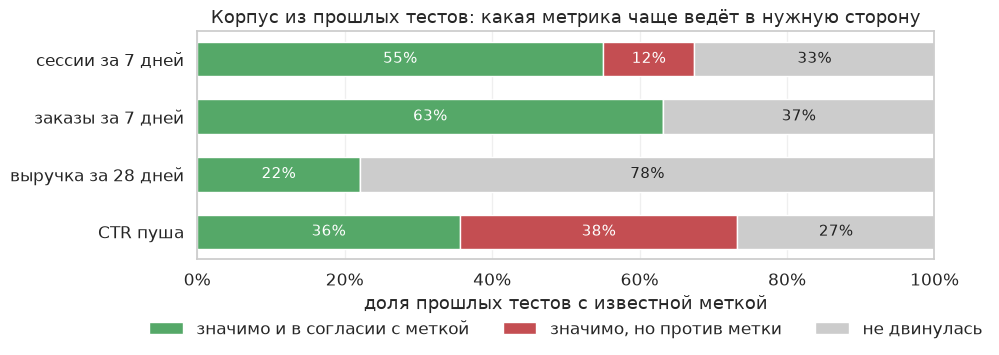

In [43]:
fig, ax = plt.subplots(figsize=(10, 3.9))
order = table.index[::-1]
left = np.zeros(len(order))
for column, color, label in [('согласие с меткой', GREEN, 'значимо и в согласии с меткой'), ('против метки', RED, 'значимо, но против метки'), ('не двинулась', '#CCCCCC', 'не двинулась')]:
    values = table.loc[order, column].values
    ax.barh(order, values, left=left, color=color, label=label, height=.6)
    for position, (value, start) in enumerate(zip(values, left)):
        if value > .07:
            ax.text(start + value / 2, position, f'{100 * value:.0f}%', ha='center', va='center', color='#222222' if color == '#CCCCCC' else 'white', fontsize=10.5)
    left += values
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel('доля прошлых тестов с известной меткой')
ax.set_title('Корпус из прошлых тестов: какая метрика чаще ведёт в нужную сторону')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.2), ncol=3, frameon=False)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

In [44]:
spread = pd.concat([corpus_metrics(make_corpus(np.random.default_rng(seed)))['согласие с меткой'].rename(seed) for seed in range(100, 150)], axis=1).T
spread_against = pd.concat([corpus_metrics(make_corpus(np.random.default_rng(seed)))['против метки'].rename(seed) for seed in range(100, 150)], axis=1).T
print('Разброс по 50 корпусам (5-й, 50-й и 95-й перцентили):')
print(pd.DataFrame({'согласие, 5%': spread.quantile(.05), 'согласие, 50%': spread.quantile(.5), 'согласие, 95%': spread.quantile(.95),
                    'против, 50%': spread_against.quantile(.5)}).round(2).to_string())

Разброс по 50 корпусам (5-й, 50-й и 95-й перцентили):
                    согласие, 5%  согласие, 50%  согласие, 95%  против, 50%
метрика                                                                    
сессии за 7 дней            0.55           0.60           0.65         0.12
заказы за 7 дней            0.57           0.63           0.67         0.00
выручка за 28 дней          0.18           0.21           0.25         0.00
CTR пуша                    0.33           0.38           0.43         0.34


Как читать результат.

* **Заказы за 7 дней** значимы в 63% размеченных тестов и ни разу не двигаются против метки. Это лучший из четырёх кандидатов: надёжный OEC.
* **Сессии за 7 дней** чувствительнее (67%), зато в 12% размеченных тестов значимо идут против метки, то есть почти каждый пятый значимый результат ведёт в неверную сторону: их накручивают так же, как в разделе о законе Гудхарта. Такая метрика годится как диагностическая, но не как единственная.
* **Выручка за 28 дней** всегда смотрит в правильную сторону, но чувствительность низкая: она значима лишь в 22% тестов. Для неё нужны дольше идущие тесты или методы ускорения (например, CUPED из базового курса).
* **CTR пуша** значим часто (73%) и при этом врёт: направление совпадает с меткой в 36% размеченных тестов и противоречит ей в 38%, то есть направление случайно. Это типичная локальная метрика, по которой нельзя принимать решения.

Конкретные проценты зависят от того, как мы задали корпус (доля накрутки, шумы), но порядок метрик устойчив: на 50 других корпусах согласие с меткой у заказов за 7 дней остаётся около 57–67%, а у сессий около 55–65% при стабильных 12% против метки. Реальный корпус придётся собирать самим: берут запущенные эксперименты, у которых итог подтвердился отдельной проверкой (долгосрочный holdout, повторный запуск, ручная оценка).

Если корпуса нет, например продукт молодой, остаётся менее надёжный путь: намеренно ухудшить опыт небольшой доле пользователей и посмотреть, заметит ли метрика ухудшение. Про такой подход, помимо корпуса экспериментов, пишут Deng и Shi ([KDD 2016](https://doi.org/10.1145/2939672.2939700)).

### Прокси и суррогаты: одной корреляции мало

Если north star недоступна за время теста, ищут **прокси**: быструю метрику, которая её предсказывает. Типичный способ: посчитать корреляцию между доступными метриками и north star, взять самую коррелированную.

**Вопрос.** Скорость загрузки главной на уровне пользователей коррелирует с числом заказов на 0.9. Аналитик предлагает использовать скорость как прокси для заказов и принимать решения только по ней. В чём риск?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Корреляция пользователей не доказывает, что эффект на скорость переносится на заказы. Она говорит, что быстрые пользователи заказывают больше, но не говорит, что ускорение приложения заставит заказывать больше. Быстрые пользователи могут просто жить в районах с хорошей сетью и высоким доходом. Для прокси нужна связь между **эффектами экспериментов**: на корпусе прошлых тестов проверить, что тесты, ускорявшие приложение, двигали заказы. Кроме того, прокси верно предсказывает только тот тип изменений, на котором проверен: ускорение клиента и новый рекомендательный блок могут влиять на заказы совсем по-разному.

</details>

Почему одной корреляции мало, покажем на примере. Возьмём заказы за первые 7 дней как кандидата на прокси для заказов за 90 дней. На уровне пользователей связь прекрасная: активные пользователи активны и в первую неделю, и потом.

In [45]:
rng = np.random.default_rng(11)
n_users = 20000
activity = rng.gamma(2.0, .5, n_users)  # скрытая активность пользователя
orders_7d = rng.poisson(3 * activity)
orders_90d = rng.poisson(25 * activity)
user_corr = np.corrcoef(orders_7d, orders_90d)[0, 1]
print(f'Корреляция заказов за 7 и за 90 дней на уровне пользователей: {user_corr:.2f}')

Корреляция заказов за 7 и за 90 дней на уровне пользователей: 0.74


Корреляция высокая (около 0.74), и кажется, что прокси готов. Но решение принимается по **эффекту воздействия**, а не по уровню метрики. Проверим, как связаны эффекты на 7-дневные и 90-дневные заказы по 150 прошлым тестам. Среди них 20% тестов — промо-акции со скидкой: они подтягивают спрос из будущего, то есть быстро поднимают заказы в первую неделю, а за 90 дней дают ноль или минус, потому что пользователи просто купили раньше.

In [46]:
def make_surrogate_tests(rng, n=150, promo_share=.2):
    """Эффекты в % на первые 7 и на 90 дней в прошлых тестах: обычные изменения и промо-акции."""
    promo = rng.random(n) < promo_share
    short = np.where(promo, rng.normal(12, 3, n), rng.normal(0, 3, n))
    long_ = np.where(promo, rng.normal(-1, 1.5, n), .7 * short + rng.normal(0, .8, n))
    return pd.DataFrame({'short': short, 'long': long_, 'promo': promo})


tests = make_surrogate_tests(np.random.default_rng(3))
usual = tests[~tests.promo]
slope, intercept = np.polyfit(usual.short, usual.long, 1)
r2_all = np.corrcoef(tests.short, tests.long)[0, 1] ** 2
r2_usual = np.corrcoef(usual.short, usual.long)[0, 1] ** 2
promo_mean = tests[tests.promo][['short', 'long']].mean()
print(f'R² между эффектами по всем тестам: {r2_all:.2f}')
print(f'R² только по обычным изменениям: {r2_usual:.2f}')
print(f'Для промо линия обычных тестов предсказала бы эффект на 90 дней {intercept + slope * promo_mean.short:+.1f}%, а на деле {promo_mean.long:+.1f}%')

R² между эффектами по всем тестам: 0.08
R² только по обычным изменениям: 0.87
Для промо линия обычных тестов предсказала бы эффект на 90 дней +8.1%, а на деле -1.1%


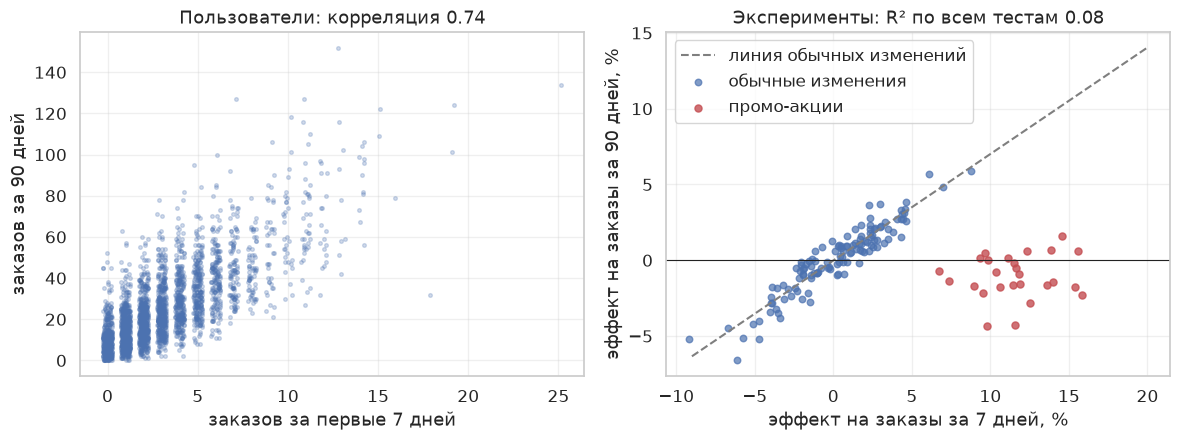

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
sample = np.random.default_rng(0).choice(n_users, 3000, replace=False)
axes[0].scatter(orders_7d[sample] + np.random.default_rng(1).uniform(-.25, .25, len(sample)), orders_90d[sample], s=7, alpha=.25, color=BLUE)
axes[0].set_title(f'Пользователи: корреляция {user_corr:.2f}')
axes[0].set_xlabel('заказов за первые 7 дней')
axes[0].set_ylabel('заказов за 90 дней')
grid = np.linspace(-9, 20, 50)
axes[1].plot(grid, intercept + slope * grid, color=GRAY, linestyle='--', label='линия обычных изменений')
axes[1].scatter(usual.short, usual.long, s=22, color=BLUE, alpha=.7, label='обычные изменения')
axes[1].scatter(tests[tests.promo].short, tests[tests.promo].long, s=26, color=RED, alpha=.8, label='промо-акции')
axes[1].axhline(0, color='#222222', linewidth=.8)
axes[1].set_title(f'Эксперименты: R² по всем тестам {r2_all:.2f}')
axes[1].set_xlabel('эффект на заказы за 7 дней, %')
axes[1].set_ylabel('эффект на заказы за 90 дней, %')
axes[1].legend(loc='upper left')
plt.tight_layout()
plt.show()

Левый график убеждает, правый показывает, что убеждаться было не в чем. Для обычных изменений эффекты действительно ложатся на линию (R² около 0.87), но по всем тестам R² падает до 0.08: промо-акции лежат в стороне, у них большой эффект на 7 дней (около +12%) и отрицательный на 90 (около −1%), а линия обычных тестов обещала бы им примерно +8%. Если выбрать прокси по корреляции пользователей и принять решение по первой неделе, мы будем уверенно запускать акции, которые не приносят ничего.

Формально суррогат работает, если эффект воздействия на долгий исход **проходит только через суррогат** (условие Прентиса). Промо нарушает его: у акции есть собственный путь к долгому исходу, мимо первой недели. Athey, Chetty, Imbens и Kang ([NBER, 2019](https://nber.org/papers/w26463.pdf)) обобщают идею на несколько суррогатов, оценивают предсказанное значение долгого исхода (суррогатный индекс) и предлагают способы проверять предположения на дополнительных наблюдаемых исходах.

На практике из этого следует несколько правил:

* **Прокси проверяют на уровне экспериментов, а не пользователей.** Нужен корпус прошлых тестов, где известны оба эффекта.
* **Прокси применимы только к типам изменений, на которых они проверены.** Для акций, скидок и всего, что «перетягивает» спрос во времени, нужна отдельная проверка.
* **Несовершенный суррогат раздувает ложные срабатывания.** Duan, Ba и Zhang ([LinkedIn, WSDM 2021](https://arxiv.org/abs/2106.01421)) показывают, что обычный A/B-тест по метрике-суррогату даёт высокую долю ложных срабатываний, потому что суррогат редко идеально предсказывает цель, и предлагают поправки к сравнению.

### Горизонт теста и долгосрочные эффекты

**Вопрос.** В акции со скидкой за первые три дня теста заказы выросли на 10%, p < 0.001. Продакт просит остановить тест и запускать на всех. Что вы ответите?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Решение по первым трём дням принимать рано: сначала нужно понять, не перетянула ли акция спрос из будущего (пользователи просто купили раньше). Для этого продолжаем тест после окончания акции и смотрим эффект по неделям, а также заказы за более длинный горизонт (14 и 28 дней) у тех же пользователей. Дополнительно проверяем, как акция повлияла на маржу и на заказы без скидки: если пользователи привыкли ждать скидку, долгосрочный эффект может быть отрицательным. Решение по первым трём дням не принимаем: рост за короткое окно после промо характерен для переноса спроса, а не для реального роста.

</details>

Даже хорошая OEC измеряет эффект за время теста, а он может меняться. Покажем на нашем кейсе с пушами: пользователи сначала реагируют на навязчивые уведомления (эффект новизны), потом устают и отписываются.

Смоделируем 8 недель теста на 100 тысяч пользователей в каждой группе. Недельное число заказов подчиняется пуассоновскому закону, а пуши умножают его интенсивность: эффект +6% в первую неделю постепенно затухает и переходит в −1.5%.

In [48]:
def weekly_effects(rng, n=100000, weeks=8):
    """Относительный эффект пушей на недельные заказы по неделям теста (с 95% ДИ) и объединённый эффект недель 5–8."""
    base = rng.gamma(2.0, .3, n)
    base_t = rng.gamma(2.0, .3, n)
    control, test, rows = [], [], []
    for week in range(weeks):
        multiplier = 1 + (-0.015 + 0.075 * np.exp(-week / 1.3))
        a = rng.poisson(base).astype(float)
        b = rng.poisson(base_t * multiplier).astype(float)
        control.append(a)
        test.append(b)
        effect, se = rel_effect(a, b)
        rows.append({'неделя': week + 1, 'эффект': effect, 'низ': effect - 1.96 * se, 'верх': effect + 1.96 * se, 'истина': multiplier - 1})
    return pd.DataFrame(rows), rel_effect(np.sum(control[4:], axis=0), np.sum(test[4:], axis=0))


weekly, (late_effect, late_se) = weekly_effects(np.random.default_rng(5))
print(weekly.assign(**{c: (100 * weekly[c]).round(1) for c in ['эффект', 'низ', 'верх', 'истина']}).to_string(index=False))
true_late = weekly[weekly['неделя'] >= 5]['истина'].mean()
print(f'\nОбъединённый эффект недель 5–8: {pct(late_effect)} (95% ДИ {pct(late_effect - 1.96 * late_se)}; {pct(late_effect + 1.96 * late_se)}), истина {pct(true_late)}')

 неделя  эффект  низ  верх  истина
      1     6.8  5.5   8.2     6.0
      2     2.3  0.9   3.6     2.0
      3    -1.2 -2.5   0.0     0.1
      4    -0.6 -1.8   0.7    -0.8
      5    -1.5 -2.8  -0.2    -1.2
      6    -1.6 -2.9  -0.3    -1.3
      7    -1.2 -2.4   0.1    -1.4
      8    -1.9 -3.2  -0.7    -1.5

Объединённый эффект недель 5–8: -1.6% (95% ДИ -2.4%; -0.7%), истина -1.3%


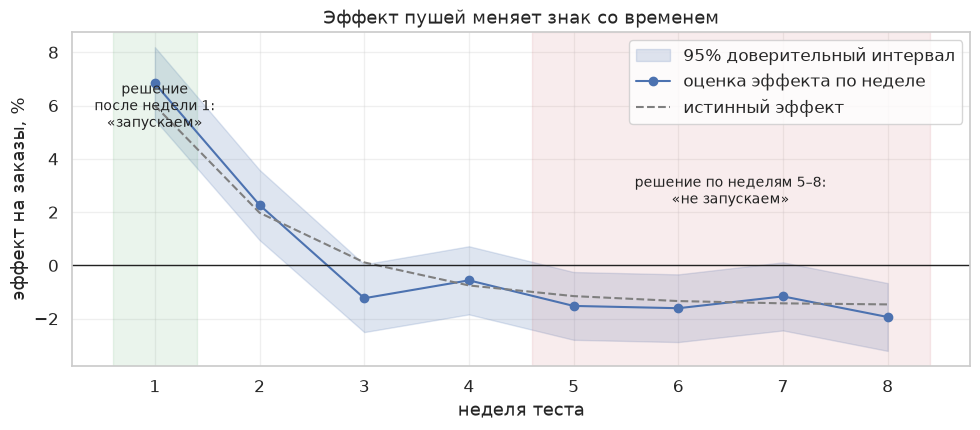

In [49]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.fill_between(weekly['неделя'], 100 * weekly['низ'], 100 * weekly['верх'], color=BLUE, alpha=.18, label='95% доверительный интервал')
ax.plot(weekly['неделя'], 100 * weekly['эффект'], color=BLUE, marker='o', label='оценка эффекта по неделе')
ax.plot(weekly['неделя'], 100 * weekly['истина'], color=GRAY, linestyle='--', label='истинный эффект')
ax.axhline(0, color='#222222', linewidth=1)
ax.axvspan(.6, 1.4, color=GREEN, alpha=.12)
ax.text(1, 6.9, 'решение\nпосле недели 1:\n«запускаем»', ha='center', va='top', fontsize=10, color='#222222')
ax.axvspan(4.6, 8.4, color=RED, alpha=.1)
ax.text(6.5, 3.4, 'решение по неделям 5–8:\n«не запускаем»', ha='center', va='top', fontsize=10, color='#222222')
ax.set_xlabel('неделя теста')
ax.set_ylabel('эффект на заказы, %')
ax.set_title('Эффект пушей меняет знак со временем')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

Решения после первой недели и по неделям 5–8 противоположны: в первую неделю эффект около +7% при интервале примерно от +5.5 до +8, а объединённый эффект недель 5–8 около −1.6% с интервалом от −2.4 до −0.7%. Знак меняется уже к третьей неделе. Если остановить тест на пике новизны, мы запустим вредное изменение.

Против этого работают три приёма.

* **Минимальная длительность** теста, привязанная к циклу поведения пользователей (не меньше полного недельного цикла и до затухания новизны). Новизну и эффект ранних пользователей выявляют по когортам: эффект считают отдельно для пользователей, впервые попавших в тест в разные дни.
* **Долгосрочный holdout.** После запуска небольшую долю пользователей (на практике единицы процентов) оставляют на старой версии и месяцами сравнивают с остальными. Так проверяют, не расходится ли долгосрочный эффект с тестовым.
* **Модель долгого эффекта по короткому.** Hohnhold, O'Brien и Tang ([Google, KDD 2015](https://research.google/pubs/focus-on-the-long-term-its-better-for-users-and-business/)) измеряли долгосрочное обучение пользователей на рекламе в поиске: пользователи со временем реже кликают на рекламу после показа некачественной, поэтому рост выручки от большего числа объявлений в краткосрочном тесте оборачивается потерями позже. Они строят модель, предсказывающую долгий эффект по коротким метрикам, и на её основе меняют аукцион.

Эти приёмы работают вместе с прокси из прошлого раздела: прокси проверяют на корпусе, а долгосрочный holdout даёт новые наблюдения для этого корпуса.

### Потеря телеметрии

Клиентские события приходят на сервер не все: мобильное приложение копит их в буфере и отправляет пачкой при подходящей сети, а если буфер переполняется, старые события теряются. Если потеря в группах разная, метрики на клиентских событиях смещены.

Так было в эксперименте Skype из той же статьи: новый протокол пушей оставлял приложение «проснувшимся» на пару секунд дольше, этого хватало, чтобы чаще успеть отправить буфер. В тесте потеряно было меньше событий, и звонковые метрики значимо изменились, хотя звонки эксперимент затрагивать не должен был. Метрики двигались непохоже на обычное улучшение или ухудшение: одни сильно, а связанные с ними не двигались вовсе.

Моделируем: в нашем кейсе изменили способ доставки событий. Реальное число заказов не изменилось, но в тесте теряется 20% клиентских событий вместо 35%.

In [50]:
def simulate_telemetry(rng, n=20000, loss=(.35, .20)):
    """Реальные заказы одинаковы в группах; клиентский лог теряет часть событий, потеря в группах разная."""
    rows = {}
    for arm, rate in zip(('контроль', 'тест'), loss):
        true_orders = rng.poisson(3, n)
        logged = rng.binomial(true_orders, 1 - rate)
        rows[arm] = dict(server=true_orders, client=logged)
    return rows


tele = simulate_telemetry(np.random.default_rng(4))
c, t = tele['контроль'], tele['тест']
client_eff = rel_effect(c['client'].astype(float), t['client'].astype(float))
server_eff = rel_effect(c['server'].astype(float), t['server'].astype(float))
users_with = [np.mean(x['client'] > 0) for x in (c, t)]
chi = st.chi2_contingency([[np.sum(x['client'] > 0), np.sum(x['client'] == 0)] for x in (c, t)])
print(f'Заказы на пользователя по клиентскому логу: {pct(client_eff[0])} (SE {100 * client_eff[1]:.1f} п.п.)')
print(f'Заказы на пользователя на сервере:          {pct(server_eff[0])} (SE {100 * server_eff[1]:.1f} п.п.)')
print(f'Доля пользователей хотя бы с одним клиентским заказом: {100 * users_with[0]:.1f}% и {100 * users_with[1]:.1f}%, p = {chi[1]:.1e}')

Заказы на пользователя по клиентскому логу: +22.9% (SE 0.8 п.п.)
Заказы на пользователя на сервере:          +0.5% (SE 0.6 п.п.)
Доля пользователей хотя бы с одним клиентским заказом: 86.3% и 91.1%, p = 1.4e-51


По клиентскому логу тест «поднял» заказы на 23%, а на сервере разницы нет (+0.5% при стандартной ошибке 0.6 п.п.). Заметить это помогают три проверки.

* **Сверка клиентских событий с серверными** (при возможности). Клиентский лог может терять и дублировать события, а сервер фиксирует каждую оплату.
* **Метрики качества данных:** доля пользователей, у которых вообще есть хоть одно событие, и число событий на пользователя в группах. Здесь они значимо различаются: хотя бы одно клиентское событие есть у 86% пользователей в контроле и у 91% в тесте.
* **Непохожий узор.** Если одни метрики двигаются сильно, а связанные с ними нет, подозрение падает на измерение, а не на поведение.

Телеметрия, на которой потеря различается, делает практически недействительными все метрики, посчитанные по затронутым событиям.

### Неполные воронки

Многие пути пользователя устроены как воронка: открыл корзину, нажал «Оплатить», оплата прошла. Лёгкий способ улучшить метрику на одном шаге — сместить внимание пользователя на него. В Microsoft в экспериментах на Xbox с промо-акциями небольшие изменения картинок и текстов сильно повышали клики по распродаже, но выручка не росла, при том что мощности хватало ([Dmitriev и др., 2017](https://www.microsoft.com/en-us/research/uploads/prod/2020/08/2017-08-KDDMetricInterpretationPitfalls.pdf)). Пользователи просто тратили лишнее время.

Поэтому в воронке нужно считать **оба вида метрик по всем шагам**: условные (доля прошедших шаг среди дошедших до него) и безусловные (доля прошедших шаг среди всех, кто начал воронку).

Новая кнопка оплаты в нашем кейсе: она заметнее, на неё нажимают чаще, но платёж проходит реже, потому что часть пользователей жмёт случайно и сдаётся на странице банка.

In [51]:
def simulate_funnel(rng, n=50000):
    """Воронка корзина → клик «Оплатить» → успешная оплата. В тесте клик чаще, а оплата среди кликнувших реже."""
    rows = {}
    for arm, click_rate, success_rate in (('контроль', .50, .85), ('тест', .60, .70)):
        click = rng.random(n) < click_rate
        success = click & (rng.random(n) < success_rate)
        rows[arm] = dict(click=click.astype(float), success=success.astype(float))
    return rows


funnel = simulate_funnel(np.random.default_rng(6))
c, t = funnel['контроль'], funnel['тест']
click_eff = rel_effect(c['click'], t['click'])
cond_eff = rel_effect(c['success'][c['click'] > 0], t['success'][t['click'] > 0])
uncond_eff = rel_effect(c['success'], t['success'])
steps = pd.DataFrame({'шаг': ['клик «Оплатить» (безусловно)', 'оплата среди кликнувших (условно)', 'оплата среди всех (безусловно)'],
                      'контроль': [c['click'].mean(), c['success'][c['click'] > 0].mean(), c['success'].mean()],
                      'тест': [t['click'].mean(), t['success'][t['click'] > 0].mean(), t['success'].mean()],
                      'эффект': [click_eff[0], cond_eff[0], uncond_eff[0]], 'SE': [click_eff[1], cond_eff[1], uncond_eff[1]]})
print(steps.assign(контроль=(100 * steps['контроль']).round(1), тест=(100 * steps['тест']).round(1), эффект=steps['эффект'].map(pct), SE=(100 * steps['SE']).round(1)).to_string(index=False))

                              шаг  контроль  тест эффект  SE
     клик «Оплатить» (безусловно)      50.3  60.5 +20.4% 0.7
оплата среди кликнувших (условно)      84.7  69.5 -18.0% 0.4
   оплата среди всех (безусловно)      42.6  42.0  -1.2% 0.7


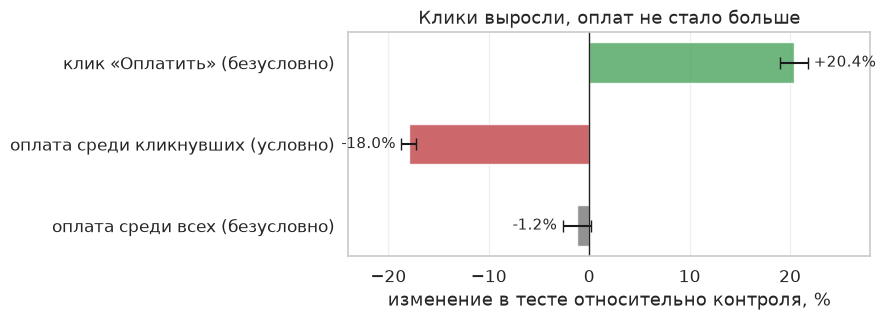

In [52]:
fig, ax = plt.subplots(figsize=(9, 3.4))
colors = [GREEN, RED, GRAY]
for k, (row, color) in enumerate(zip(steps.itertuples(), colors)):
    ax.barh(k, 100 * row.эффект, xerr=196 * row.SE, color=color, alpha=.85, height=.5, capsize=4)
    ax.text(100 * row.эффект + np.sign(row.эффект) * (196 * row.SE + .6), k, pct(row.эффект), va='center', ha='left' if row.эффект > 0 else 'right', fontsize=11)
ax.axvline(0, color='#222222', linewidth=1)
ax.set_yticks(range(3))
ax.set_yticklabels(steps['шаг'])
ax.invert_yaxis()
ax.set_xlim(-24, 28)
ax.set_xlabel('изменение в тесте относительно контроля, %')
ax.set_title('Клики выросли, оплат не стало больше')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

Если смотреть только на клик, тест выигрывает на 20%. Условная метрика показывает причину: среди кликнувших платёж проходит реже на 18%. Безусловная метрика даёт итог: оплат не стало больше (−1.2% при стандартной ошибке 0.7 п.п., то есть в пределах шума). Клик по кнопке остаётся диагностической метрикой и не годится для решения.

### Закон Твайман

Все ловушки выше объединяет одно правило, которое Microsoft формулирует в духе закона Твайман: любое необычное движение метрики, хорошее или плохое, чаще всего означает проблему. Мы склонны скептически смотреть на неожиданный минус и радоваться неожиданному плюсу, а проверять надо оба.

**Вопрос.** В тесте нового экрана клики по главной кнопке выросли на 28%, число заказов не изменилось, а эффект по дням быстро убывает. Что вы скажете команде?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Запускать по кликам нельзя: рост кликов без роста заказов при быстро затухающем эффекте больше похож на новизну или путаницу, чем на улучшение. Возможная гипотеза: кнопка ведёт не туда, куда привыкли пользователи, и они кликают повторно; её стоит проверить по повторным кликам одних и тех же пользователей. Решение по кликам принимать нельзя. Смотрим OEC и guardrail-метрики (удержание, отписки, жалобы), анализируем эффект по дням и когортам, проверяем, нет ли роста повторных кликов у одних и тех же пользователей. Если OEC не изменилась и не улучшилась, изменение запускать не нужно, а команде полезно разобраться, чем именно запутался интерфейс.

</details>

Пример из той же статьи: на главной MSN кнопку Outlook.com заменили на кнопку почтового приложения. Клики по странице выросли на 4.7%, клики по самой кнопке на 28%, и ещё на 27% по соседней. Казалось, что тест превзошёл ожидания. Но метрики удержания и удовлетворённости не изменились, а клики по кнопке быстро падали день ото дня. Пользователи привыкли, что кнопка ведёт на Outlook.com, не понимали, что она открывает другое приложение, и кликали снова и по соседней кнопке тоже. Эксперимент закрыли до конца срока, чтобы не раздражать людей.

В нашем кейсе другой сценарий: ошибка логирования. В новой версии iOS-приложения каждая покупка записывается в клиентский лог дважды. Сам заказ один, на сервере всё в порядке.

In [53]:
def simulate_duplicate_logging(rng, n=30000):
    """Реальных различий нет. В тесте у iOS (40% пользователей) клиент пишет каждую покупку дважды."""
    rows = []
    for arm, doubled in (('контроль', False), ('тест', True)):
        ios = rng.random(n) < .4
        purchases = rng.poisson(.5, n)
        revenue_per_purchase = rng.gamma(4, 120, n)
        server_revenue = purchases * revenue_per_purchase
        multiplier = np.where(ios & doubled, 2, 1)
        rows.append(pd.DataFrame({'arm': arm, 'ios': ios, 'server_purchases': purchases, 'client_purchases': purchases * multiplier,
                                  'server_revenue': server_revenue, 'client_revenue': server_revenue * multiplier}))
    return pd.concat(rows)


dup = simulate_duplicate_logging(np.random.default_rng(8))
rows = []
for column, label in (('client_revenue', 'выручка на пользователя (клиент)'), ('server_revenue', 'выручка на пользователя (сервер)'),
                      ('client_purchases', 'покупок на пользователя (клиент)'), ('server_purchases', 'покупок на пользователя (сервер)')):
    a, b = dup.loc[dup.arm == 'контроль', column], dup.loc[dup.arm == 'тест', column]
    effect, se = rel_effect(a, b)
    rows.append({'метрика': label, 'эффект': pct(effect), 'p-value': f'{diff_p(a, b)[2]:.1e}'})
print(pd.DataFrame(rows).to_string(index=False))
ratio = dup.groupby(['arm', 'ios']).apply(lambda g: g.client_purchases.sum() / g.server_purchases.sum(), include_groups=False).unstack().rename(columns={False: 'Android', True: 'iOS'})
print('\nОтношение клиентских покупок к серверным по платформам:')
print(ratio.round(2).to_string())

                         метрика эффект  p-value
выручка на пользователя (клиент) +39.4% 2.0e-112
выручка на пользователя (сервер)  -0.1%  9.5e-01
покупок на пользователя (клиент) +39.9% 4.7e-157
покупок на пользователя (сервер)  +0.3%  8.3e-01

Отношение клиентских покупок к серверным по платформам:
ios       Android  iOS
arm                   
контроль      1.0  1.0
тест          1.0  2.0


По клиентскому логу тест обещает рост выручки на десятки процентов при заранее ожидаемом эффекте в единицы процентов, а на сервере разницы нет. Подозрение вызывает уже масштаб: эффект в разы превышает всё, что мы закладывали при планировании. Локализуется причина разрезом по платформам и сверкой с сервером: у iOS в тесте клиент пишет ровно вдвое больше событий, чем сервер, а у Android всё сходится.

Практическое правило, которое сэкономит больше всего ошибочных запусков: **чем лучше результат, тем тщательнее его проверять.** Если эффект в разы больше ожидаемого MDE, это повод искать ошибку (логирование, дубли, сегмент по сломанному признаку), а не праздновать.

## Источники

1. [Dmitriev, Gupta, Kim, Vaz. A Dirty Dozen: Twelve Common Metric Interpretation Pitfalls in Online Controlled Experiments (KDD 2017)](https://www.microsoft.com/en-us/research/uploads/prod/2020/08/2017-08-KDDMetricInterpretationPitfalls.pdf): все реальные примеры Microsoft.
2. [Dmitriev, Wu. Measuring Metrics (CIKM 2016)](https://exp-platform.com/Documents/2016CIKM_MeasuringMetrics.pdf): чувствительность, согласие с метками, корпус экспериментов.
3. [Deng, Shi. Data-Driven Metric Development for Online Controlled Experiments: Seven Lessons Learned (KDD 2016)](https://doi.org/10.1145/2939672.2939700).
4. [Deng, Hu. Diluted Treatment Effect Estimation for Trigger Analysis in Online Controlled Experiments (WSDM 2015)](https://exp-platform.com/dilution/).
5. [Crook, Frasca, Kohavi, Longbotham. Seven Pitfalls to Avoid when Running Controlled Experiments on the Web (KDD 2009)](https://exp-platform.com/seven-pitfalls/).
6. [Athey, Chetty, Imbens, Kang. The Surrogate Index (NBER w26463)](https://nber.org/papers/w26463.pdf).
7. [Duan, Ba, Zhang. Online Experimentation with Surrogate Metrics: Guidelines and a Case Study (WSDM 2021)](https://arxiv.org/abs/2106.01421).
8. [Hohnhold, O'Brien, Tang. Focusing on the Long-term: It's Good for Users and Business (KDD 2015)](https://research.google/pubs/focus-on-the-long-term-its-better-for-users-and-business/).
9. Kohavi, Tang, Xu. Trustworthy Online Controlled Experiments (Cambridge University Press, 2020).
10. Georgi Z. Georgiev. Statistical Methods in Online A/B Testing, глава 6.
11. [Schultzberg, Ankargren, Frånberg. Risk-aware product decisions in A/B tests with multiple metrics (Spotify, 2024)](https://arxiv.org/abs/2402.11609): правило запуска по метрикам успеха, guardrail, ухудшения и качества.
12. [Campelo, Wanner. Расчёт размера выборки при множественных сравнениях (2020)](https://link.springer.com/article/10.1007/s10732-020-09454-w).
13. Benjamini, Hochberg. Controlling the False Discovery Rate (1995); Benjamini, Yekutieli. The control of the false discovery rate in multiple testing under dependency (2001).
14. [Поправки на множественное тестирование в A/B-тестах (X5 Tech, Хабр)](https://habr.com/ru/companies/X5Tech/articles/842426/) и [Оптимальное разбиение трафика по группам (X5 Tech, Хабр)](https://habr.com/ru/companies/X5Tech/articles/763656/).